# Notebook 09 — Interpretability Analysis

This notebook completes the Week 10 interpretability analysis for the **depression** and **anxiety** classifiers. It does not retrain or retune a model. For each task, it reads the Week 9 benchmark results, selects the **point-estimate PR-AUC leader**, and loads that run's **best-validation checkpoint**.

All tables and figures are produced **separately for depression and anxiety**. The notebook creates:

- model-agnostic SHAP explanations for representative test notes;
- attention visualisations for the same type of representative samples;
- ranked clinical-language markers from the 65+ cohort;
- a literature-based clinical plausibility screen;
- dashboard-ready PNG/SVG figures, CSV tables and a methodology write-up.

Interpretation boundary: SHAP and attention describe model behaviour. They do **not** establish causality, diagnosis, clinical importance or feature validity. Markers must be reviewed by a qualified clinician before they are presented as clinically meaningful.


## 1. Run instructions

1. Keep the completed Week 9 outputs and each selected run's `best_model` directory under `model_outputs`.
2. Run once with `INTERPRETABILITY_RUN_MODE=smoke` to verify paths and GPU memory.
3. Run again with `INTERPRETABILITY_RUN_MODE=full` for the deliverable.
4. If a dependency is missing, uncomment the installation command in the next cell, run it once, restart the kernel and run all cells.

The defaults explain up to two notes from each available outcome group (TP, TN, FP and FN) in full mode. This is intentionally a representative audit sample rather than a population-wide causal analysis.


In [1]:
# Uncomment only if the environment is missing a required package.
# %pip install -U shap transformers sentencepiece safetensors pyarrow seaborn scipy


In [2]:
from pathlib import Path
import gc
import json
import os
import platform
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
try:
    import shap
except ImportError as error:
    raise ImportError("SHAP is required. Run the installation cell, restart the kernel and run all cells.") from error
from scipy.stats import spearmanr
from transformers import AutoModelForSequenceClassification, AutoTokenizer
try:
    from IPython.display import HTML, Markdown, display
except ImportError:
    HTML = Markdown = str
    display = print

SEED = 42
RUN_MODE = os.getenv("INTERPRETABILITY_RUN_MODE", "full").lower()
if RUN_MODE not in {"smoke", "full"}:
    raise ValueError("INTERPRETABILITY_RUN_MODE must be 'smoke' or 'full'.")
TASKS = ["depression", "anxiety"]
MODEL_ORDER = ["ClinicalBERT", "RoBERTa", "DeBERTa", "Clinical Longformer"]
MODEL_COLORS = {"ClinicalBERT": "#2F6690", "RoBERTa": "#3A7D44",
                "DeBERTa": "#D17A22", "Clinical Longformer": "#7A5195"}
FORCE_MODEL_BY_TASK = {"depression": None, "anxiety": None}
SHAP_SAMPLES_PER_OUTCOME = 1 if RUN_MODE == "smoke" else 2
ATTENTION_SAMPLES_PER_OUTCOME = 1
SHAP_MAX_EVALS = 160 if RUN_MODE == "smoke" else 600
SHAP_CALL_BATCH_SIZE = 4
TOP_LOCAL_MARKERS = 18
TOP_GLOBAL_MARKERS = 25
TOP_ATTENTION_MARKERS = 20
MIN_MARKER_LENGTH = 3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")
display(HTML("<style>.output_scroll{height:auto!important;max-height:none!important;overflow-y:visible!important}"
             ".jp-OutputArea-child.jp-mod-scrolled,.jp-OutputArea-output{max-height:none!important;overflow-y:visible!important}</style>"))
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("SHAP:", shap.__version__)
print("Run mode:", RUN_MODE)
print("Device:", DEVICE)
print("SHAP samples per available outcome:", SHAP_SAMPLES_PER_OUTCOME)
print("SHAP maximum evaluations per note:", SHAP_MAX_EVALS)


Python: 3.13.9
PyTorch: 2.13.0
SHAP: 0.52.0
Run mode: full
Device: cpu
SHAP samples per available outcome: 2
SHAP maximum evaluations per note: 600


## 2. Project paths and output structure

The run-directory names match Notebook 08. Change only the explicit run-name mapping if your folder names differ. The checkpoint resolver accepts `best_model` and `deployment_bundle/model`, but never silently substitutes the final-epoch checkpoint.


In [3]:
def find_project_root(starting_path):
    starting_path = Path(starting_path).expanduser().resolve()
    for location in [starting_path, *starting_path.parents]:
        if (location / "model_outputs").exists() or (location / "dataset").exists() or (location / ".git").exists():
            return location
    return starting_path

PROJECT_ROOT = find_project_root(Path.cwd())
MODEL_OUTPUT_ROOT = PROJECT_ROOT / "model_outputs"
WEEK9_ROOT = MODEL_OUTPUT_ROOT / "comparative_evaluation"
OUTPUT_ROOT = MODEL_OUTPUT_ROOT / "interpretability_analysis"
TASK_DIRS = {task: {kind: OUTPUT_ROOT / task / kind for kind in ["tables", "figures", "html", "dashboard"]}
             for task in TASKS}
for task in TASKS:
    for directory in TASK_DIRS[task].values():
        directory.mkdir(parents=True, exist_ok=True)

LONGFORMER_RUN_NAMES = {
    "depression": "clinical_longformer_depression_masked_selected_2048_full",
    "anxiety": "clinical_longformer_anxiety_masked_selected_2048_full",
}
def resolve_longformer_directory(task):
    base = MODEL_OUTPUT_ROOT / "clinical_longformer"
    configured = base / LONGFORMER_RUN_NAMES[task]
    if configured.exists():
        return configured
    candidates = sorted(base.glob(f"clinical_longformer_{task}_masked_*_full"))
    if len(candidates) == 1:
        return candidates[0]
    if len(candidates) > 1:
        raise ValueError(f"Multiple Clinical Longformer runs found for {task}: {[str(path) for path in candidates]}")
    return configured

def build_run_directories(task):
    return {
        "ClinicalBERT": MODEL_OUTPUT_ROOT / "clinicalbert_finetuned" / task,
        "RoBERTa": MODEL_OUTPUT_ROOT / "roberta_finetuned" / task,
        "DeBERTa": MODEL_OUTPUT_ROOT / "deberta_finetuned" / task,
        "Clinical Longformer": MODEL_OUTPUT_ROOT / "clinical_longformer_finetuned" / task,
    }

RUN_DIRECTORIES = {task: build_run_directories(task) for task in TASKS}
DATASET_PATHS = {task: PROJECT_ROOT / "dataset" / "model_datasets" / f"{task}_dataset_masked.parquet" for task in TASKS}
print("Project root:", PROJECT_ROOT)
print("Interpretability output root:", OUTPUT_ROOT)


Project root: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection
Interpretability output root: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/interpretability_analysis


## 3. Select the Week 9 best-performing model

The primary selection rule is the highest common-cohort test PR-AUC recorded by Week 9. A manual override is available in Section 1, but it should be documented if used. The table also retains models that Week 9 found statistically indistinguishable from the point-estimate leader.


In [4]:
def read_json(path, required=False):
    if not path.exists():
        if required:
            raise FileNotFoundError(path)
        return {}
    with open(path, "r", encoding="utf-8") as input_file:
        return json.load(input_file)

selection_rows = []
best_model_by_task = {}
for task in TASKS:
    summary_path = WEEK9_ROOT / task / "tables" / "best_model_summary.csv"
    ranking_path = WEEK9_ROOT / task / "tables" / "model_ranking.csv"
    source_path = summary_path if summary_path.exists() else ranking_path
    if not source_path.exists():
        raise FileNotFoundError(f"Missing Week 9 best-model table for {task}: {summary_path}")
    frame = pd.read_csv(source_path)
    if "model" not in frame or "pr_auc" not in frame:
        raise ValueError(f"{source_path} must contain model and pr_auc columns.")
    frame = frame.sort_values(["pr_auc"], ascending=False).reset_index(drop=True)
    forced_model = FORCE_MODEL_BY_TASK[task]
    selected_model = forced_model or str(frame.iloc[0]["model"])
    if selected_model not in MODEL_ORDER:
        raise ValueError(f"Unsupported model selected for {task}: {selected_model}")
    best_model_by_task[task] = selected_model
    tied_models = frame.loc[frame.get("not_distinguishable_from_leader", False).astype(bool), "model"].tolist() \
        if "not_distinguishable_from_leader" in frame else []
    selection_rows.append({"task": task, "selected_model": selected_model,
                           "selection_rule": "manual override" if forced_model else "highest Week 9 common-cohort PR-AUC",
                           "selected_pr_auc": float(frame.set_index("model").loc[selected_model, "pr_auc"]),
                           "models_not_distinguishable_from_leader": "; ".join(tied_models) or "Not recorded",
                           "week9_source": str(source_path)})
selection_table = pd.DataFrame(selection_rows)
selection_table.to_csv(OUTPUT_ROOT / "selected_models.csv", index=False)
for task in TASKS:
    display(Markdown(f"### {task.title()} model selection"))
    display(selection_table.loc[selection_table["task"].eq(task)].reset_index(drop=True).round(4))


### Depression model selection

,task,selected_model,selection_rule,selected_pr_auc,models_not_distinguishable_from_leader,week9_source
0,depression,Clinical Longformer,highest Week 9 common-cohort PR-AUC,0.7852,Clinical Longformer,/Users/purnaperamune/Documents/GitHub/P000464S...


### Anxiety model selection

,task,selected_model,selection_rule,selected_pr_auc,models_not_distinguishable_from_leader,week9_source
0,anxiety,Clinical Longformer,highest Week 9 common-cohort PR-AUC,0.7134,Clinical Longformer,/Users/purnaperamune/Documents/GitHub/P000464S...


In [5]:
def resolve_best_checkpoint(run_directory):
    manifest = read_json(run_directory / "run_manifest.json", required=True)
    candidates = [run_directory / "best_model", run_directory / "deployment_bundle" / "model"]
    manifest_path = manifest.get("best_model_directory")
    if manifest_path:
        candidates.append(Path(manifest_path))
    for candidate in candidates:
        if candidate.exists() and (candidate / "config.json").exists():
            return candidate, manifest
    expected = "\n".join(str(path) for path in candidates)
    raise FileNotFoundError(f"Best-validation checkpoint not found for {run_directory}. Checked:\n{expected}")

selected_runs = {}
checkpoint_rows = []
for task in TASKS:
    model_name = best_model_by_task[task]
    run_directory = RUN_DIRECTORIES[task][model_name]
    checkpoint, manifest = resolve_best_checkpoint(run_directory)
    selected_runs[task] = {"model": model_name, "run_directory": run_directory,
                           "checkpoint": checkpoint, "manifest": manifest}
    checkpoint_rows.append({"task": task, "model": model_name, "checkpoint_stage": "best validation",
                            "checkpoint": str(checkpoint), "text_column": manifest.get("text_column", "text_selected"),
                            "maximum_length": manifest.get("maximum_length"),
                            "best_epoch": manifest.get("best_epoch"),
                            "best_validation_pr_auc": manifest.get("best_validation_pr_auc")})
checkpoint_table = pd.DataFrame(checkpoint_rows)
checkpoint_table.to_csv(OUTPUT_ROOT / "checkpoint_audit.csv", index=False)
display(checkpoint_table)


,task,model,checkpoint_stage,checkpoint,text_column,maximum_length,best_epoch,best_validation_pr_auc
0,depression,Clinical Longformer,best validation,/Users/purnaperamune/Documents/GitHub/P000464S...,text_selected,2048,4,0.786334
1,anxiety,Clinical Longformer,best validation,/Users/purnaperamune/Documents/GitHub/P000464S...,text_selected,2048,3,0.724303


## 4. Load and align representative test samples

Representative samples are chosen separately for true positives, true negatives, false positives and false negatives. The selection uses prediction confidence only; note text is never used to choose a visually convenient example. Raw note text is not written to the output tables.


In [6]:
REQUIRED_PREDICTION_COLUMNS = {"subject_id", "hadm_id", "label", "positive_probability", "predicted_label"}
def load_task_frame(task):
    item = selected_runs[task]
    prediction_path = item["run_directory"] / "predictions" / "test_predictions.csv"
    if not prediction_path.exists():
        raise FileNotFoundError(prediction_path)
    predictions = pd.read_csv(prediction_path)
    missing = REQUIRED_PREDICTION_COLUMNS.difference(predictions.columns)
    if missing:
        raise ValueError(f"{prediction_path} is missing columns: {sorted(missing)}")
    dataset_path = DATASET_PATHS[task]
    if not dataset_path.exists():
        raise FileNotFoundError(dataset_path)
    dataset = pd.read_parquet(dataset_path)
    text_column = item["manifest"].get("text_column", "text_selected")
    required_dataset_columns = {"subject_id", "hadm_id", "split", "label", text_column}
    missing_dataset = required_dataset_columns.difference(dataset.columns)
    if missing_dataset:
        raise ValueError(f"{dataset_path} is missing columns: {sorted(missing_dataset)}")
    test = dataset.loc[dataset["split"].astype(str).str.lower().eq("test"),
                       ["subject_id", "hadm_id", "label", text_column]].copy()
    for frame in [predictions, test]:
        frame["hadm_id"] = pd.to_numeric(frame["hadm_id"], errors="raise").astype("int64")
        frame["subject_id"] = pd.to_numeric(frame["subject_id"], errors="raise").astype("int64")
        frame["label"] = pd.to_numeric(frame["label"], errors="raise").astype(int)
    if predictions["hadm_id"].duplicated().any() or test["hadm_id"].duplicated().any():
        raise ValueError(f"Duplicate test hadm_id values were found for {task}.")
    merged = predictions.merge(test, on="hadm_id", suffixes=("_prediction", "_dataset"), validate="one_to_one")
    if not merged["subject_id_prediction"].equals(merged["subject_id_dataset"]):
        raise ValueError(f"Subject IDs disagree for {task}.")
    if not merged["label_prediction"].equals(merged["label_dataset"]):
        raise ValueError(f"Labels disagree for {task}.")
    merged = merged.rename(columns={"subject_id_prediction": "subject_id", "label_prediction": "label"})
    merged = merged.drop(columns=["subject_id_dataset", "label_dataset"])
    merged[text_column] = merged[text_column].fillna("").astype(str)
    if merged[text_column].str.strip().eq("").any():
        raise ValueError(f"Empty {text_column} values found for {task}.")
    return merged, text_column

task_frames, text_columns = {}, {}
for task in TASKS:
    task_frames[task], text_columns[task] = load_task_frame(task)
    print(task.title(), "aligned test admissions:", len(task_frames[task]))


Depression aligned test admissions: 26782
Anxiety aligned test admissions: 24991


In [7]:
def add_outcome(frame):
    result = frame.copy()
    labels = result["label"].to_numpy(dtype=int)
    predictions = result["predicted_label"].to_numpy(dtype=int)
    result["outcome"] = np.select(
        [(labels == 1) & (predictions == 1), (labels == 0) & (predictions == 0),
         (labels == 0) & (predictions == 1), (labels == 1) & (predictions == 0)],
        ["TP", "TN", "FP", "FN"], default="unknown")
    return result

def choose_representative_samples(frame, samples_per_outcome):
    frame = add_outcome(frame)
    sort_rules = {"TP": ("positive_probability", False), "TN": ("positive_probability", True),
                  "FP": ("positive_probability", False), "FN": ("positive_probability", True)}
    parts = []
    for outcome in ["TP", "TN", "FP", "FN"]:
        column, ascending = sort_rules[outcome]
        candidates = frame.loc[frame["outcome"].eq(outcome)].sort_values(column, ascending=ascending)
        if not candidates.empty:
            parts.append(candidates.head(samples_per_outcome))
    if not parts:
        raise ValueError("No representative samples could be selected.")
    selected = pd.concat(parts, ignore_index=True)
    selected.insert(0, "sample_id", [f"sample_{index + 1:02d}" for index in range(len(selected))])
    return selected

representative_samples = {}
for task in TASKS:
    selected = choose_representative_samples(task_frames[task], SHAP_SAMPLES_PER_OUTCOME)
    representative_samples[task] = selected
    public_columns = ["sample_id", "subject_id", "hadm_id", "label", "predicted_label",
                      "positive_probability", "outcome"]
    selected[public_columns].to_csv(TASK_DIRS[task]["tables"] / "representative_sample_manifest.csv", index=False)
    display(Markdown(f"### {task.title()} representative samples"))
    display(selected[public_columns].round(4))


### Depression representative samples

,sample_id,subject_id,hadm_id,label,predicted_label,positive_probability,outcome
0,sample_01,16129896,27958985,1,1,0.9844,TP
1,sample_02,13051530,25579581,1,1,0.9839,TP
2,sample_03,10455613,24050094,0,0,0.0027,TN
3,sample_04,15089338,20252333,0,0,0.0027,TN
4,sample_05,14362539,28907671,0,1,0.9815,FP
5,sample_06,19050570,25970540,0,1,0.9810,FP
6,sample_07,11529731,24922042,1,0,0.0028,FN
7,sample_08,15447210,27517508,1,0,0.0029,FN


### Anxiety representative samples

,sample_id,subject_id,hadm_id,label,predicted_label,positive_probability,outcome
0,sample_01,18463042,23036334,1,1,0.9702,TP
1,sample_02,14887253,26543697,1,1,0.9698,TP
2,sample_03,13398773,28417115,0,0,0.0027,TN
3,sample_04,17244619,28797316,0,0,0.0027,TN
4,sample_05,16359771,21272623,0,1,0.9679,FP
5,sample_06,14354252,24987122,0,1,0.9635,FP
6,sample_07,19225937,29953011,1,0,0.0033,FN
7,sample_08,11496131,25795006,1,0,0.0034,FN


## 5. Model-loading and prediction helpers

Only one task model is held in GPU memory at a time. Clinical Longformer receives global attention on the first token, matching its training notebook. The forward helper returns probabilities for both labels; SHAP explains the positive-label output.


In [8]:
def load_model_bundle(task):
    item = selected_runs[task]
    checkpoint = item["checkpoint"]
    tokenizer = AutoTokenizer.from_pretrained(checkpoint, use_fast=True)
    try:
        model = AutoModelForSequenceClassification.from_pretrained(
            checkpoint, torch_dtype=MODEL_DTYPE, attn_implementation="eager")
    except (TypeError, ValueError):
        model = AutoModelForSequenceClassification.from_pretrained(checkpoint, torch_dtype=MODEL_DTYPE)
    model.to(DEVICE)
    model.eval()
    if hasattr(model.config, "use_cache"):
        model.config.use_cache = False
    maximum_length = int(item["manifest"].get("maximum_length") or min(tokenizer.model_max_length, 512))
    is_longformer = getattr(model.config, "model_type", "").lower() == "longformer"
    return tokenizer, model, maximum_length, is_longformer

def add_global_attention(encoded, is_longformer):
    if is_longformer:
        global_attention_mask = torch.zeros_like(encoded["attention_mask"])
        global_attention_mask[:, 0] = 1
        encoded["global_attention_mask"] = global_attention_mask
    return encoded

def probability_predictor(tokenizer, model, maximum_length, is_longformer):
    forward_batch_size = 1 if maximum_length > 512 else 8
    def predict(texts):
        text_list = [str(value) for value in np.asarray(texts, dtype=object).reshape(-1)]
        probabilities = []
        for start in range(0, len(text_list), forward_batch_size):
            batch = text_list[start:start + forward_batch_size]
            encoded = tokenizer(batch, truncation=True, max_length=maximum_length,
                                padding=True, return_tensors="pt")
            encoded = add_global_attention(encoded, is_longformer)
            encoded = {name: value.to(DEVICE) for name, value in encoded.items()}
            with torch.inference_mode():
                logits = model(**encoded).logits.float()
            probabilities.append(torch.softmax(logits, dim=-1).cpu().numpy())
        return np.concatenate(probabilities, axis=0)
    return predict

def release_model(*objects):
    for item in objects:
        del item
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


## 6. SHAP analysis

The notebook uses SHAP's partition explainer with the selected model's own tokenizer as the text masker. The model prediction function preserves the original maximum context length and Longformer's global-attention policy. `max_evals` limits computational cost, so reported values are approximate local attributions.

Positive SHAP values push the prediction toward the positive class; negative values push it away. Absolute SHAP magnitude is used only to rank how strongly the model relied on a marker within this audit sample.


In [9]:
SPECIAL_MARKERS = {"", "[cls]", "[sep]", "[pad]", "[mask]", "<s>", "</s>", "<pad>", "<mask>"}
STOP_MARKERS = {"the", "and", "for", "with", "that", "this", "from", "was", "were", "are", "has", "had",
                "have", "not", "but", "into", "his", "her", "she", "him", "you", "your", "our", "they",
                "them", "their", "its", "then", "than", "also", "can", "could", "would", "should", "may",
                "patient", "patients", "hospital", "admission", "discharge", "date", "name", "age", "year"}

def normalise_marker(value):
    value = str(value).replace("##", "").replace("Ġ", " ").replace("▁", " ").lower().strip()
    value = re.sub(r"[^a-z][^a-z'-]*", " ", value)
    value = re.sub(r"\s+", " ", value).strip(" '-")
    if len(value) < MIN_MARKER_LENGTH or value in SPECIAL_MARKERS or value in STOP_MARKERS:
        return ""
    if not re.search(r"[a-z]", value):
        return ""
    return value

def explanation_rows(task, samples, explanations):
    rows = []
    for sample_index, sample in samples.reset_index(drop=True).iterrows():
        tokens = np.asarray(explanations.data[sample_index], dtype=object).reshape(-1)
        values = np.asarray(explanations.values[sample_index])
        if values.ndim == 2:
            positive_values = values[:, 1] if values.shape[1] > 1 else values[:, 0]
        else:
            positive_values = values.reshape(-1)
        usable = min(len(tokens), len(positive_values))
        for position in range(usable):
            token = str(tokens[position])
            rows.append({"task": task, "model": selected_runs[task]["model"],
                         "sample_id": sample["sample_id"], "outcome": sample["outcome"],
                         "label": int(sample["label"]), "predicted_label": int(sample["predicted_label"]),
                         "positive_probability": float(sample["positive_probability"]),
                         "token_position": position, "token": token,
                         "marker": normalise_marker(token), "shap_value": float(positive_values[position]),
                         "absolute_shap_value": abs(float(positive_values[position]))})
    return pd.DataFrame(rows)

def run_shap_task(task):
    tokenizer, model, maximum_length, is_longformer = load_model_bundle(task)
    predictor = probability_predictor(tokenizer, model, maximum_length, is_longformer)
    mask_token = tokenizer.mask_token or "[MASK]"
    masker = shap.maskers.Text(tokenizer, mask_token=mask_token)
    explainer = shap.Explainer(predictor, masker, algorithm="partition",
                               output_names=["negative", "positive"])
    samples = representative_samples[task]
    texts = samples[text_columns[task]].astype(str).tolist()
    start = time.time()
    explanations = explainer(texts, max_evals=SHAP_MAX_EVALS,
                             batch_size=SHAP_CALL_BATCH_SIZE, fixed_context=1)
    rows = explanation_rows(task, samples, explanations)
    runtime = time.time() - start
    del explanations, explainer, predictor, model, tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return rows, runtime


In [10]:
shap_rows_by_task = {}
shap_runtime_rows = []
for task in TASKS:
    print(f"Running SHAP for {task} using {best_model_by_task[task]}...")
    shap_rows, runtime = run_shap_task(task)
    shap_rows_by_task[task] = shap_rows
    shap_rows.to_csv(TASK_DIRS[task]["tables"] / "local_shap_attributions.csv", index=False)
    shap_runtime_rows.append({"task": task, "model": best_model_by_task[task],
                              "samples": shap_rows["sample_id"].nunique(),
                              "maximum_evaluations_per_sample": SHAP_MAX_EVALS,
                              "runtime_minutes": runtime / 60})
    print(task.title(), "SHAP runtime (minutes):", round(runtime / 60, 2))
shap_runtime_table = pd.DataFrame(shap_runtime_rows)
shap_runtime_table.to_csv(OUTPUT_ROOT / "shap_runtime_summary.csv", index=False)
display(shap_runtime_table.round(2))


Running SHAP for depression using Clinical Longformer...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/273 [00:00<?, ?it/s]

[transformers] Input ids are automatically padded to be a multiple of `config.attention_window`: 512


  0%|          | 0/598 [00:00<?, ?it/s]

...

PartitionExplainer explainer: 100%|████████████| 8/8 [1:26:48<00:00, 696.00s/it]

  0%|          | 0/598 [00:00<?, ?it/s]

PartitionExplainer explainer: 9it [2:00:16, 902.12s/it]                         


Anxiety SHAP runtime (minutes): 120.28


,task,model,samples,maximum_evaluations_per_sample,runtime_minutes
0,depression,Clinical Longformer,8,600,67.45
1,anxiety,Clinical Longformer,8,600,120.28


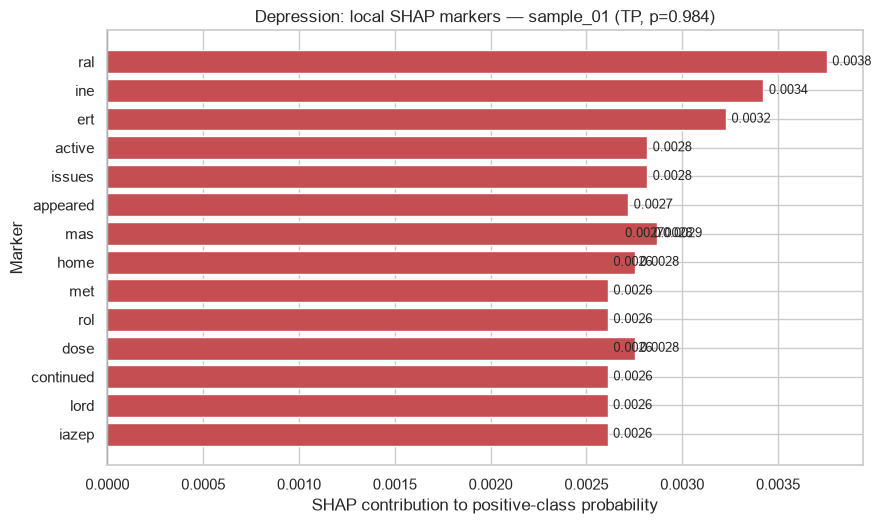

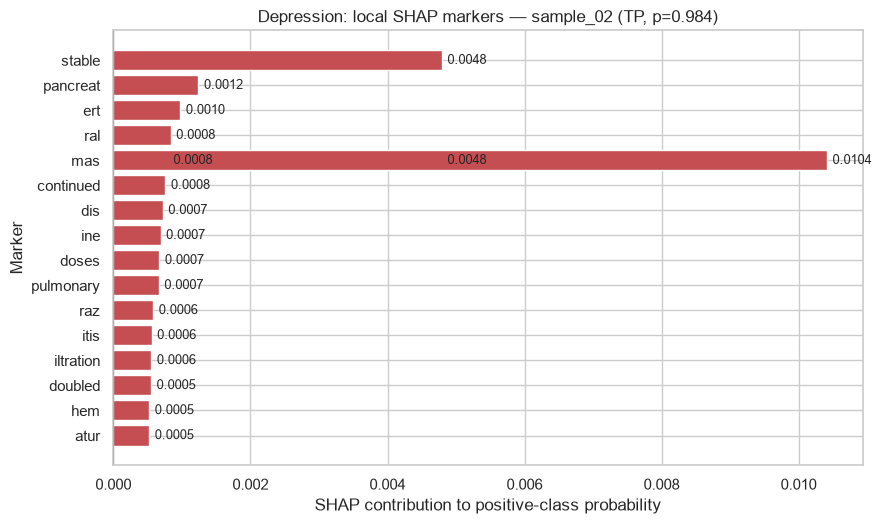

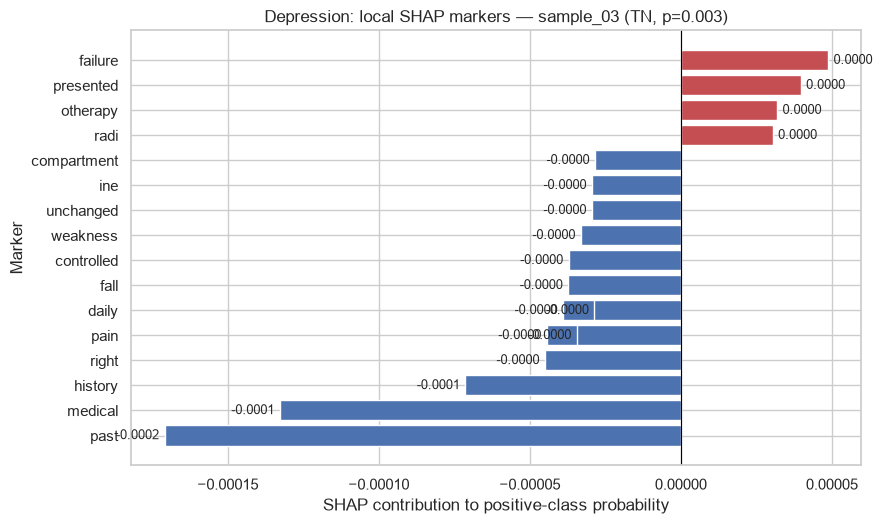

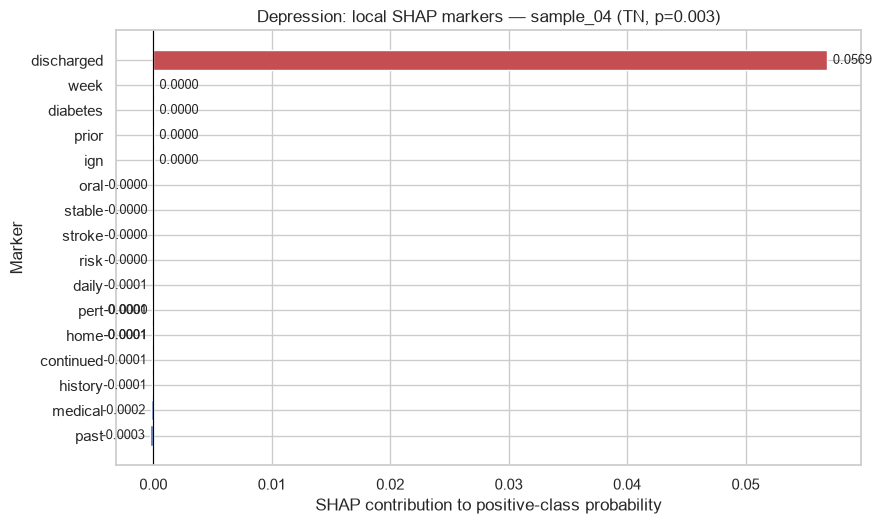

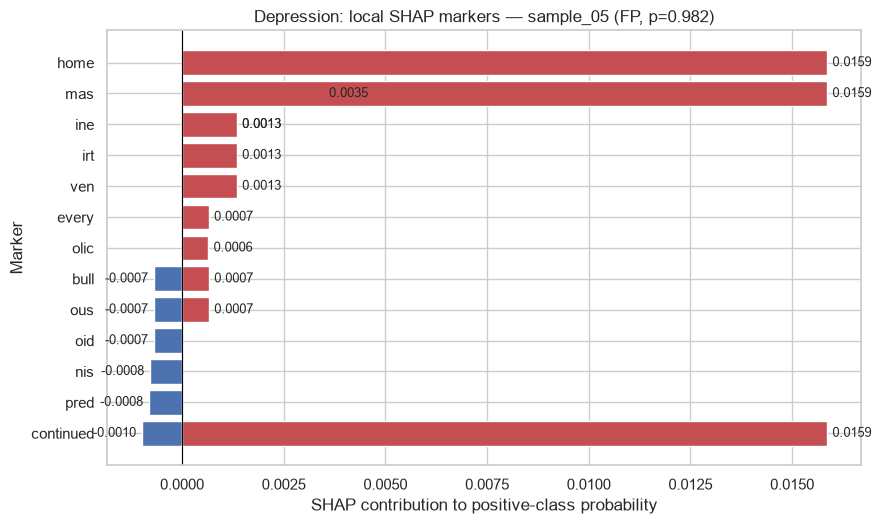

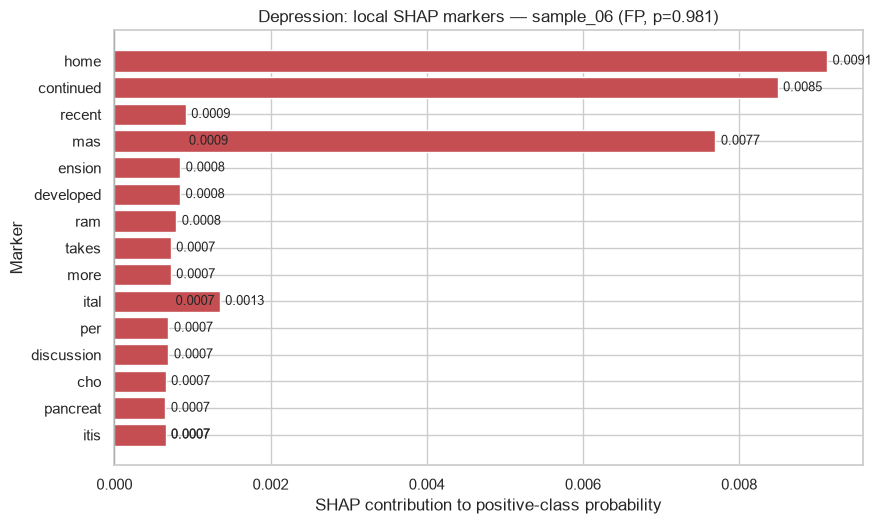

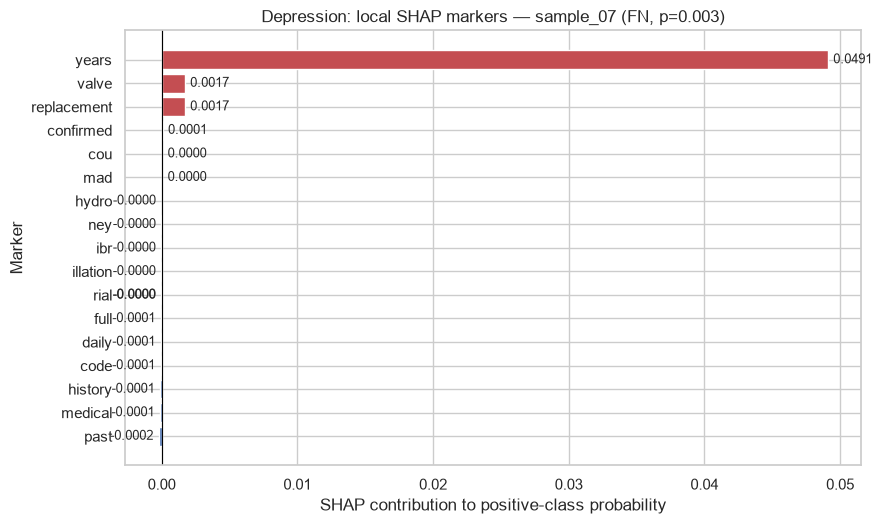

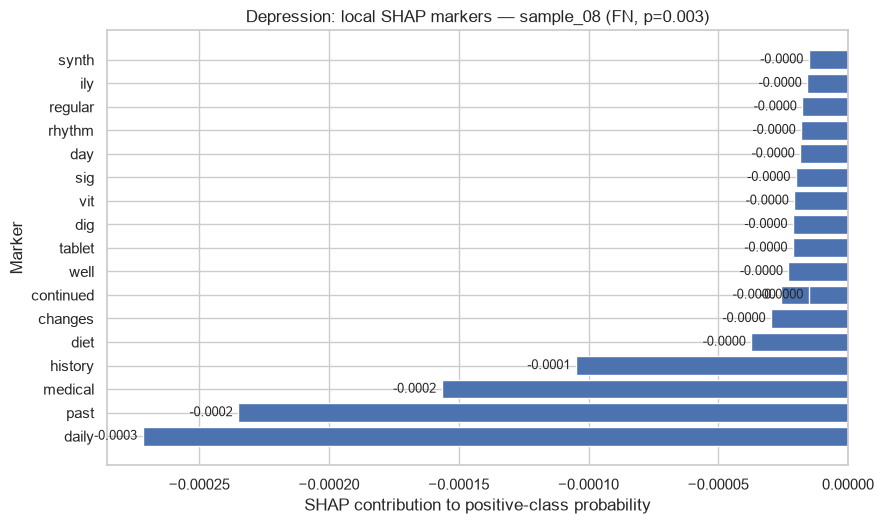

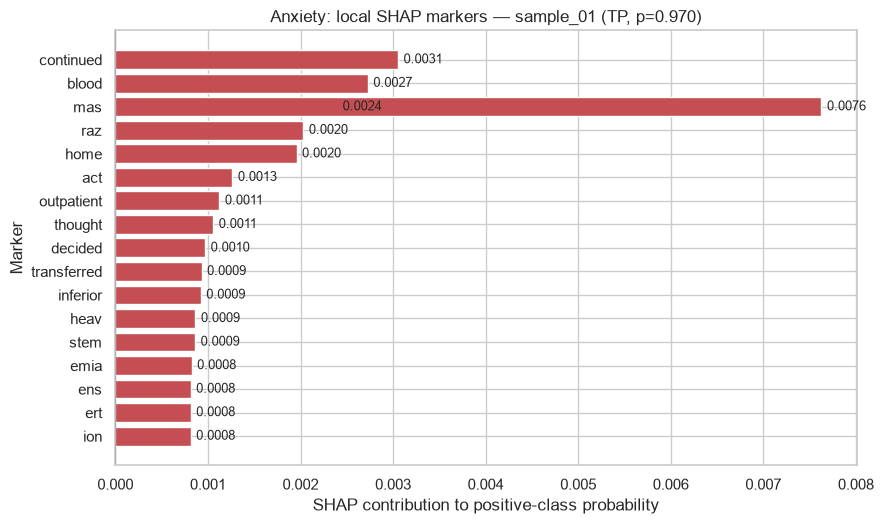

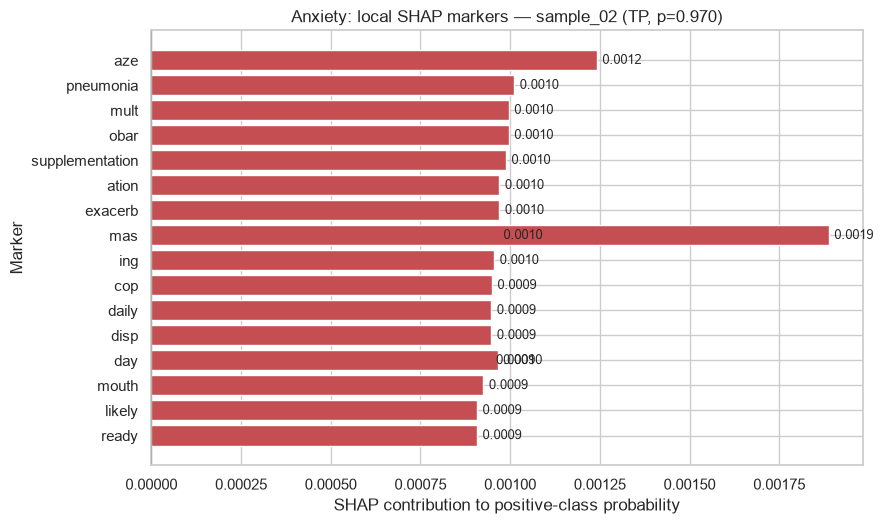

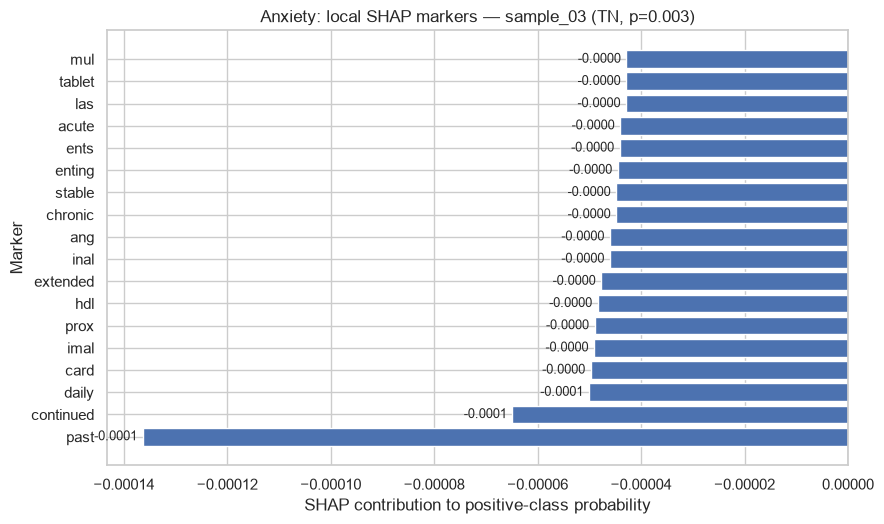

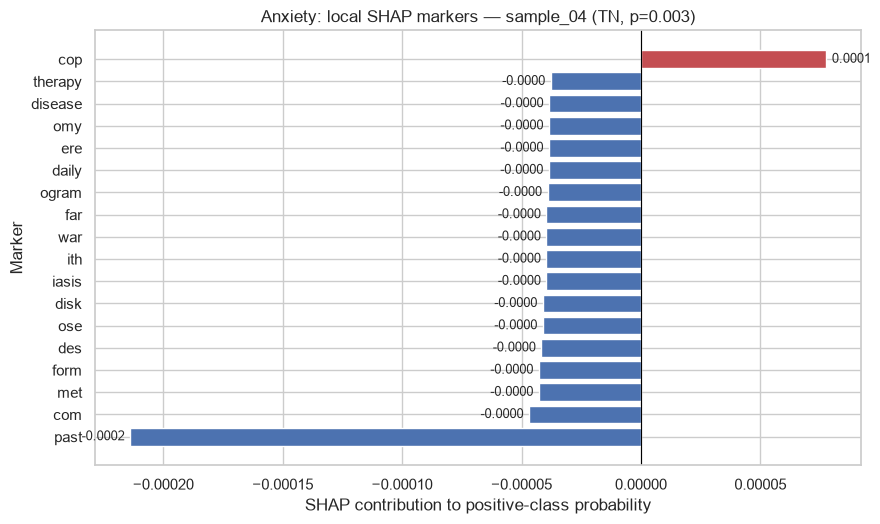

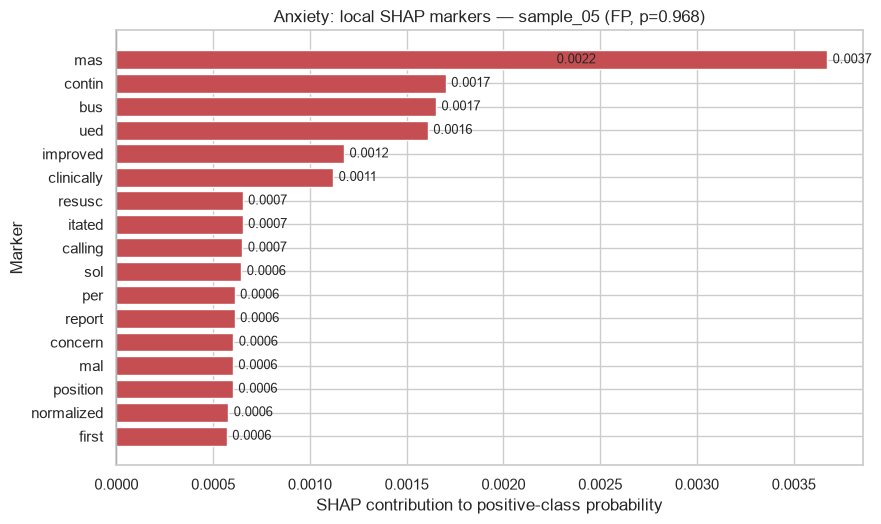

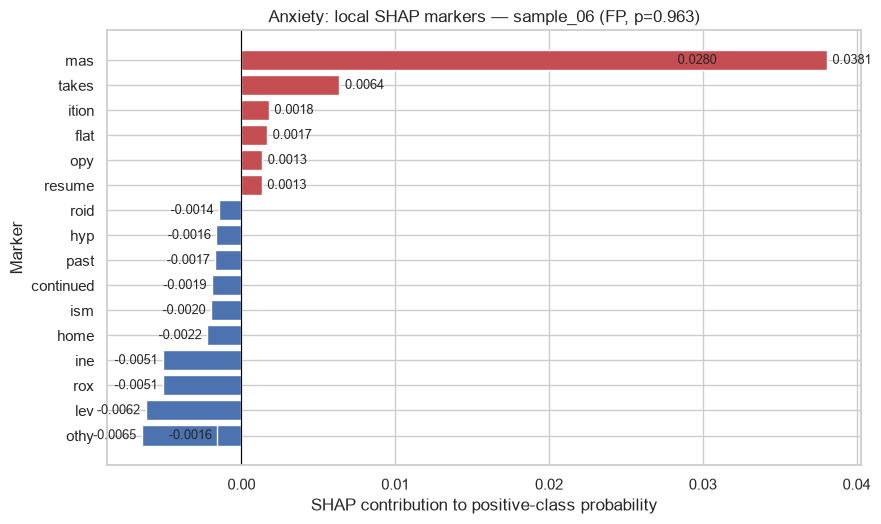

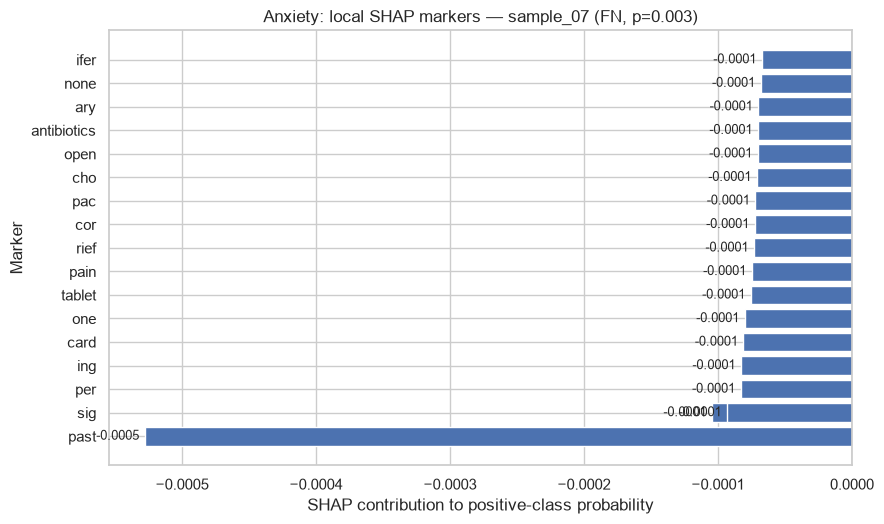

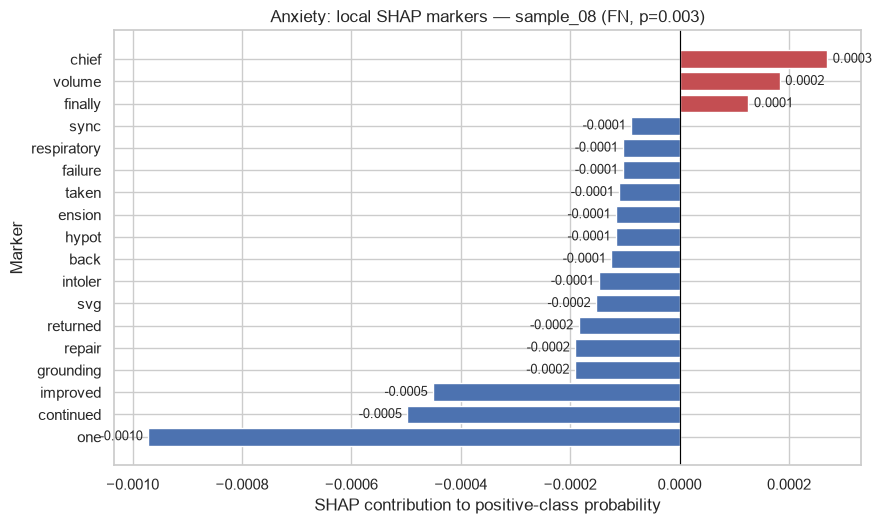

In [11]:
def save_figure(figure, task, filename):
    stem = TASK_DIRS[task]["figures"] / filename
    figure.savefig(stem.with_suffix(".png"), dpi=240, bbox_inches="tight", facecolor="white")
    figure.savefig(stem.with_suffix(".svg"), bbox_inches="tight", facecolor="white")

def label_horizontal_bars(axis, decimals=4, fontsize=9):
    for container in axis.containers:
        if hasattr(container, "patches"):
            axis.bar_label(container, fmt=f"%.{decimals}f", padding=4, fontsize=fontsize)

for task in TASKS:
    rows = shap_rows_by_task[task]
    for sample_id, sample_rows in rows.groupby("sample_id", sort=False):
        plot_rows = sample_rows.loc[sample_rows["marker"].ne("")].nlargest(TOP_LOCAL_MARKERS, "absolute_shap_value")
        if plot_rows.empty:
            continue
        plot_rows = plot_rows.sort_values("shap_value")
        colors = np.where(plot_rows["shap_value"].ge(0), "#C44E52", "#4C72B0")
        figure, axis = plt.subplots(figsize=(9, max(4.5, 0.30 * len(plot_rows))))
        axis.barh(plot_rows["marker"], plot_rows["shap_value"], color=colors)
        axis.axvline(0, color="black", linewidth=0.8)
        outcome = str(plot_rows.iloc[0]["outcome"])
        probability = float(plot_rows.iloc[0]["positive_probability"])
        axis.set(title=f"{task.title()}: local SHAP markers — {sample_id} ({outcome}, p={probability:.3f})",
                 xlabel="SHAP contribution to positive-class probability", ylabel="Marker")
        label_horizontal_bars(axis, decimals=4)
        figure.tight_layout()
        save_figure(figure, task, f"local_shap_{sample_id}")
        plt.show()
        plt.close(figure)


### Depression ranked SHAP markers

,shap_rank,marker,mean_absolute_shap,total_absolute_shap,mean_signed_shap,maximum_absolute_shap,sample_frequency,occurrence_count,model_direction
0,1,years,0.016698,0.050093,0.016698,0.049083,3,3,toward positive class
1,2,discharged,0.014484,0.057936,0.014481,0.056904,4,4,toward positive class
2,3,mas,0.003529,0.056468,0.003529,0.015854,5,16,toward positive class
3,4,appeared,0.002718,0.002718,0.002718,0.002718,1,1,toward positive class
4,5,affect,0.002541,0.002541,0.002541,0.002541,1,1,toward positive class
5,6,flat,0.002299,0.002299,0.002299,0.002299,1,1,toward positive class
6,7,home,0.001474,0.035377,0.001418,0.015854,7,24,toward positive class
7,8,iazep,0.001433,0.004299,0.001433,0.002610,1,3,toward positive class
8,9,lord,0.001375,0.004126,0.001375,0.002610,1,3,toward positive class
9,10,continued,0.001321,0.035669,0.001234,0.015854,8,27,toward positive class


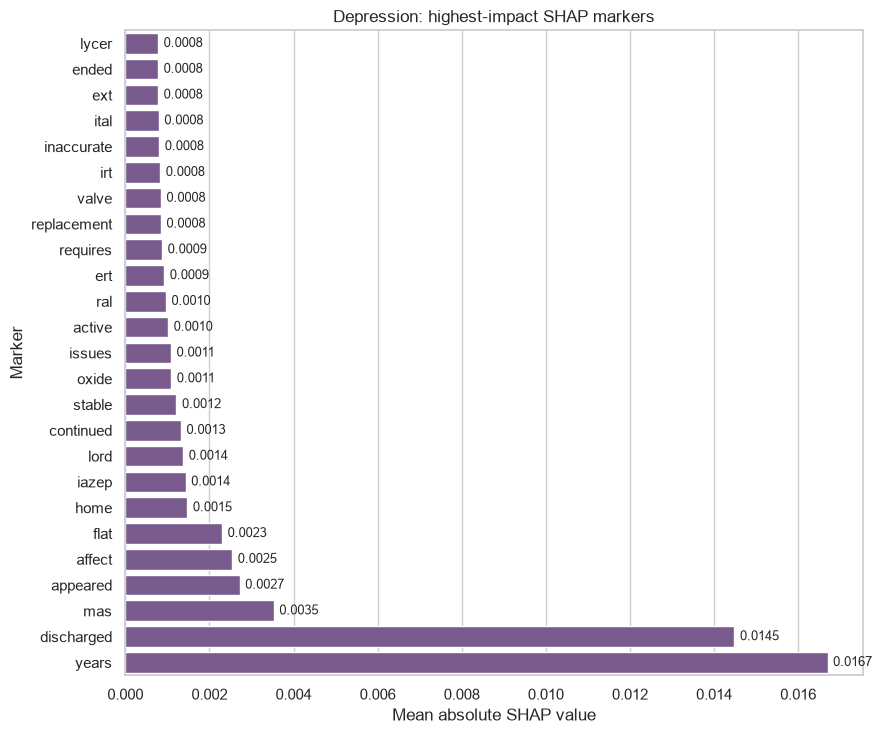

### Anxiety ranked SHAP markers

,shap_rank,marker,mean_absolute_shap,total_absolute_shap,mean_signed_shap,maximum_absolute_shap,sample_frequency,occurrence_count,model_direction
0,1,takes,0.006371,0.006371,0.006371,0.006371,1,1,toward positive class
1,2,mas,0.004041,0.092934,0.004041,0.038069,4,23,toward positive class
2,3,flat,0.001670,0.001670,0.001670,0.001670,1,1,toward positive class
3,4,taking,0.001319,0.001319,0.001319,0.001319,1,1,toward positive class
4,5,including,0.001277,0.001277,0.001277,0.001277,1,1,toward positive class
5,6,coordinating,0.001277,0.001277,0.001277,0.001277,1,1,toward positive class
6,7,find,0.001252,0.001252,0.001252,0.001252,1,1,toward positive class
7,8,ings,0.001252,0.001252,0.001252,0.001252,1,1,toward positive class
8,9,kins,0.001228,0.001228,0.001228,0.001228,1,1,toward positive class
9,10,ools,0.001166,0.001166,0.001166,0.001166,1,1,toward positive class


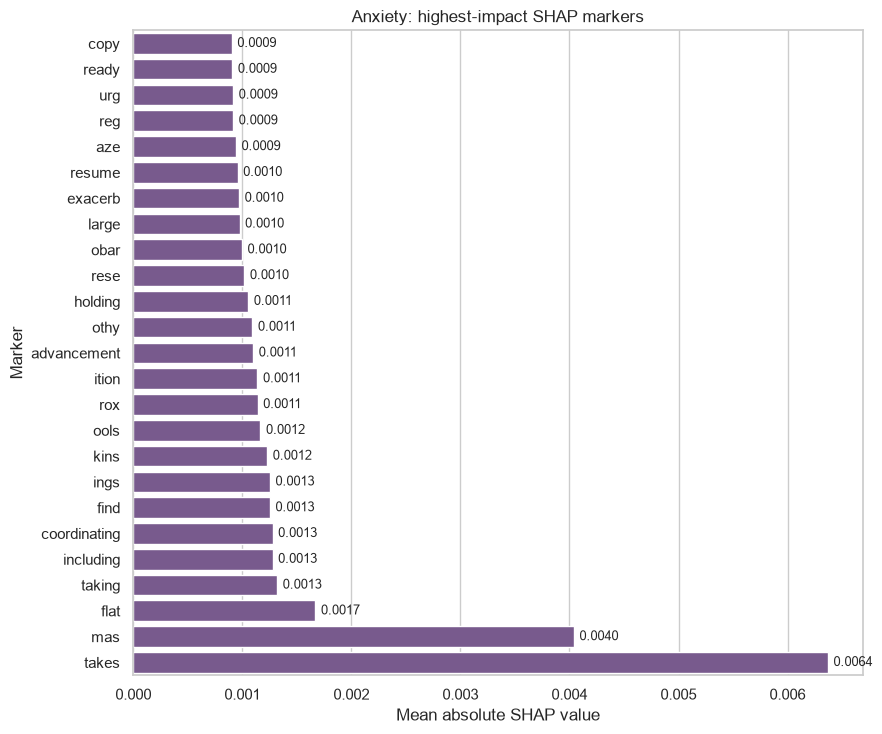

In [12]:
def build_global_shap_table(rows):
    clean = rows.loc[rows["marker"].ne("")].copy()
    grouped = clean.groupby("marker", as_index=False).agg(
        mean_absolute_shap=("absolute_shap_value", "mean"),
        total_absolute_shap=("absolute_shap_value", "sum"),
        mean_signed_shap=("shap_value", "mean"),
        maximum_absolute_shap=("absolute_shap_value", "max"),
        sample_frequency=("sample_id", "nunique"),
        occurrence_count=("marker", "size"))
    grouped = grouped.sort_values(["mean_absolute_shap", "sample_frequency"], ascending=False).reset_index(drop=True)
    grouped.insert(0, "shap_rank", np.arange(1, len(grouped) + 1))
    grouped["model_direction"] = np.where(grouped["mean_signed_shap"].ge(0),
                                           "toward positive class", "away from positive class")
    return grouped

global_shap_by_task = {}
for task in TASKS:
    table = build_global_shap_table(shap_rows_by_task[task])
    global_shap_by_task[task] = table
    table.to_csv(TASK_DIRS[task]["tables"] / "ranked_shap_markers.csv", index=False)
    display(Markdown(f"### {task.title()} ranked SHAP markers"))
    display(table.head(TOP_GLOBAL_MARKERS).round(6))
    plot_rows = table.head(TOP_GLOBAL_MARKERS).sort_values("mean_absolute_shap")
    figure, axis = plt.subplots(figsize=(9, max(6, 0.30 * len(plot_rows))))
    sns.barplot(data=plot_rows, x="mean_absolute_shap", y="marker", color=MODEL_COLORS[best_model_by_task[task]], ax=axis)
    axis.set(title=f"{task.title()}: highest-impact SHAP markers",
             xlabel="Mean absolute SHAP value", ylabel="Marker")
    label_horizontal_bars(axis, decimals=4)
    figure.tight_layout()
    save_figure(figure, task, "global_shap_marker_ranking")
    plt.show()
    plt.close(figure)


## 7. Attention visualisation

For standard transformer classifiers, the score is the last-layer mean attention from the first classification token. For Clinical Longformer, the score is the last-layer mean **global attention** associated with the first globally attended token. If a model exposes only local sparse attention, the fallback is the mean local-attention mass associated with each token.

Attention is shown as a complementary diagnostic, not as a feature-importance proof.


In [13]:
def extract_attention_scores(tokenizer, model, text, maximum_length, is_longformer):
    encoded = tokenizer(str(text), truncation=True, max_length=maximum_length, return_tensors="pt")
    encoded = add_global_attention(encoded, is_longformer)
    active_length = int(encoded["attention_mask"][0].sum())
    input_ids = encoded["input_ids"][0, :active_length].tolist()
    tokens = tokenizer.convert_ids_to_tokens(input_ids)
    device_inputs = {name: value.to(DEVICE) for name, value in encoded.items()}
    with torch.inference_mode():
        outputs = model(**device_inputs, output_attentions=True, return_dict=True)
    scores, method = None, None
    global_attentions = getattr(outputs, "global_attentions", None)
    if global_attentions:
        attention = global_attentions[-1].float().cpu()
        if attention.shape[-1] >= active_length and attention.shape[-2] < active_length:
            scores = attention[0, :, 0, :active_length].mean(dim=0).numpy()
        elif attention.shape[-2] >= active_length and attention.shape[-1] < active_length:
            scores = attention[0, :, :active_length, 0].mean(dim=0).numpy()
        method = "last-layer mean global attention"
    if scores is None:
        attentions = getattr(outputs, "attentions", None)
        if not attentions:
            raise ValueError("The selected model did not return attention tensors.")
        attention = attentions[-1].float().cpu()
        if attention.shape[-2] >= active_length and attention.shape[-1] >= active_length:
            scores = attention[0, :, 0, :active_length].mean(dim=0).numpy()
            method = "last-layer mean CLS attention"
        else:
            scores = attention[0, :, :active_length, :].mean(dim=(0, 2)).numpy()
            method = "last-layer mean local sparse attention"
    scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    scores = np.clip(scores, 0, None)
    if scores.sum() > 0:
        scores = scores / scores.sum()
    rows = []
    for position, (token, score) in enumerate(zip(tokens[:len(scores)], scores)):
        rows.append({"token_position": position, "token": token,
                     "marker": normalise_marker(token), "attention_score": float(score),
                     "attention_method": method})
    return pd.DataFrame(rows)

def run_attention_task(task):
    tokenizer, model, maximum_length, is_longformer = load_model_bundle(task)
    samples = choose_representative_samples(task_frames[task], ATTENTION_SAMPLES_PER_OUTCOME)
    parts = []
    for _, sample in samples.iterrows():
        scores = extract_attention_scores(tokenizer, model, sample[text_columns[task]], maximum_length, is_longformer)
        scores.insert(0, "sample_id", sample["sample_id"])
        scores.insert(1, "outcome", sample["outcome"])
        scores.insert(2, "positive_probability", float(sample["positive_probability"]))
        parts.append(scores)
    del model, tokenizer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return pd.concat(parts, ignore_index=True)


In [14]:
attention_rows_by_task = {}
for task in TASKS:
    print(f"Extracting attention for {task} using {best_model_by_task[task]}...")
    rows = run_attention_task(task)
    attention_rows_by_task[task] = rows
    rows.to_csv(TASK_DIRS[task]["tables"] / "local_attention_scores.csv", index=False)
    print(task.title(), "attention samples:", rows["sample_id"].nunique())


Extracting attention for depression using Clinical Longformer...


Loading weights:   0%|          | 0/273 [00:00<?, ?it/s]

Depression attention samples: 4
Extracting attention for anxiety using Clinical Longformer...


Loading weights:   0%|          | 0/273 [00:00<?, ?it/s]

Anxiety attention samples: 4


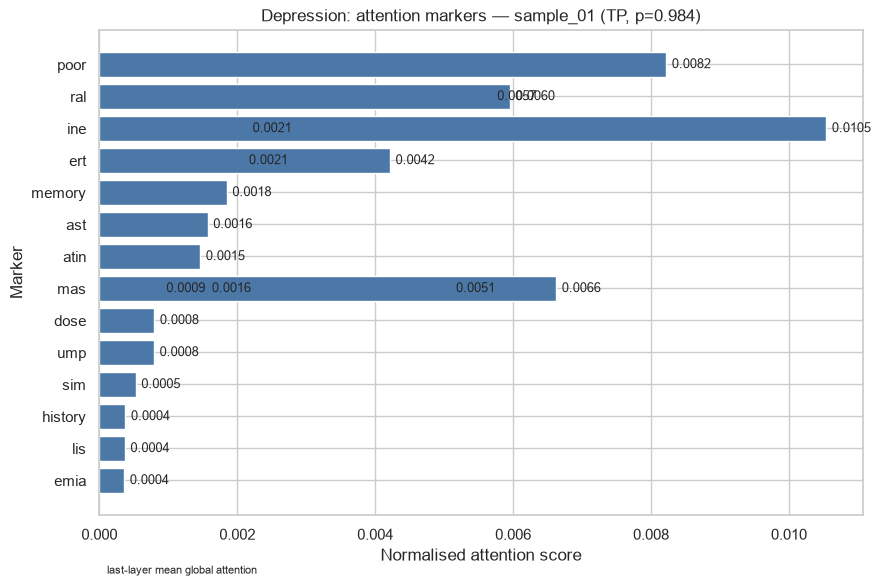

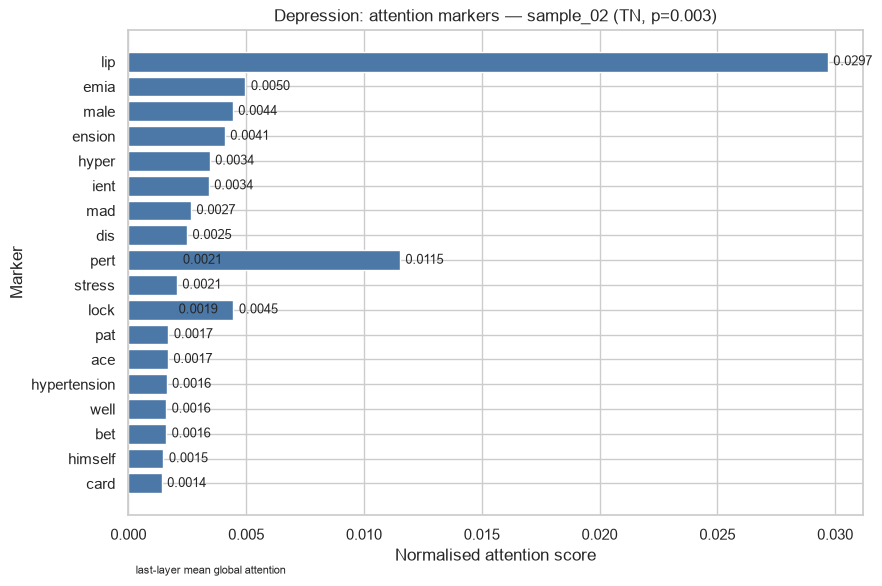

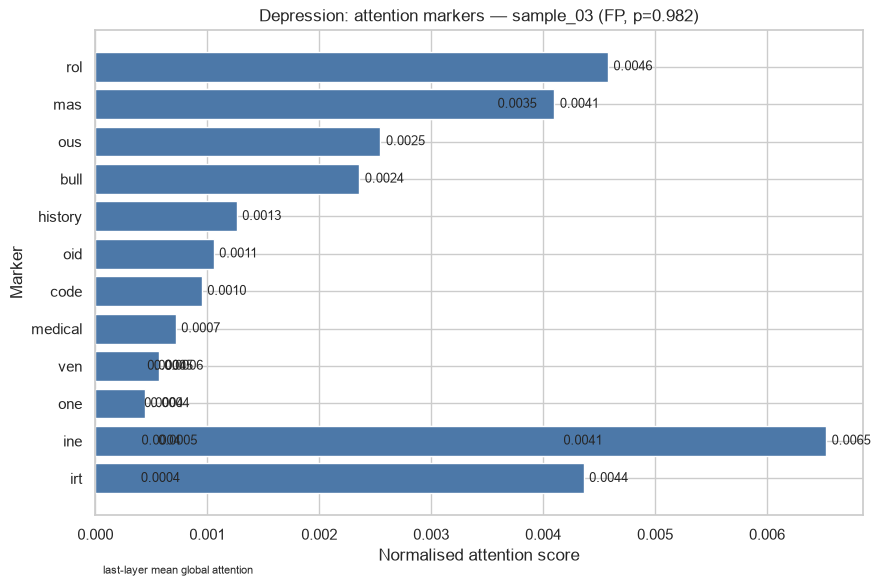

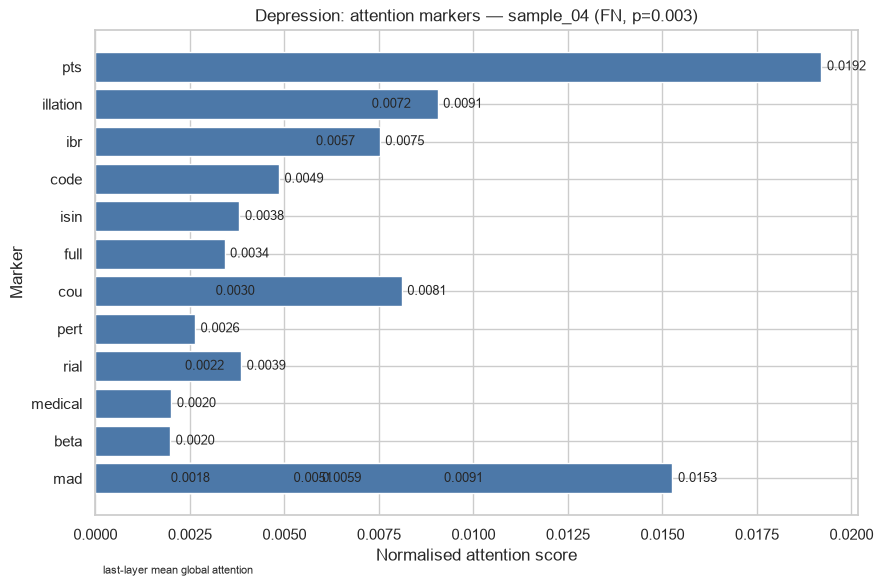

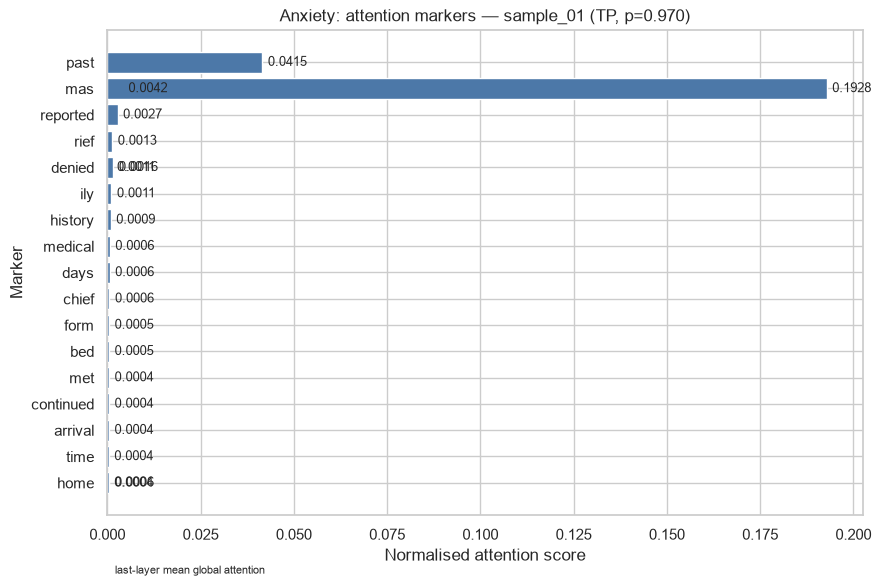

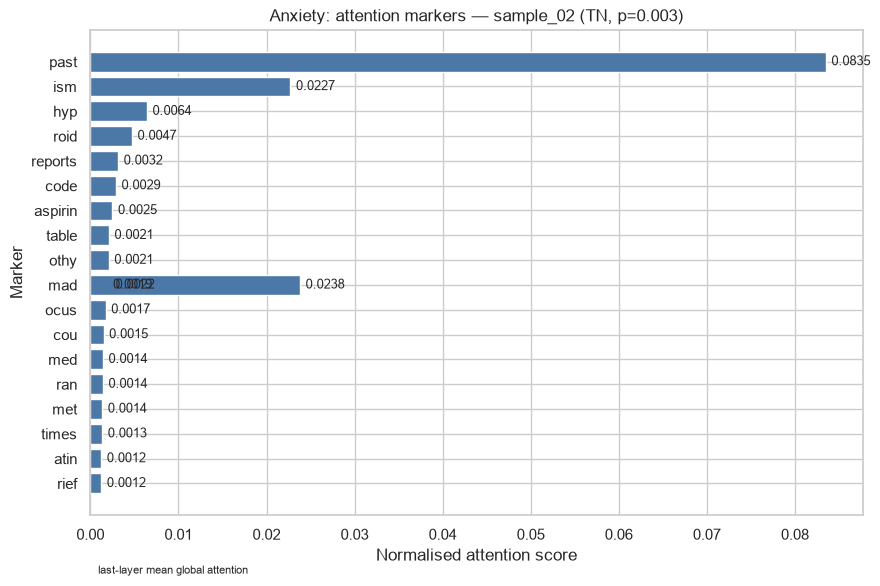

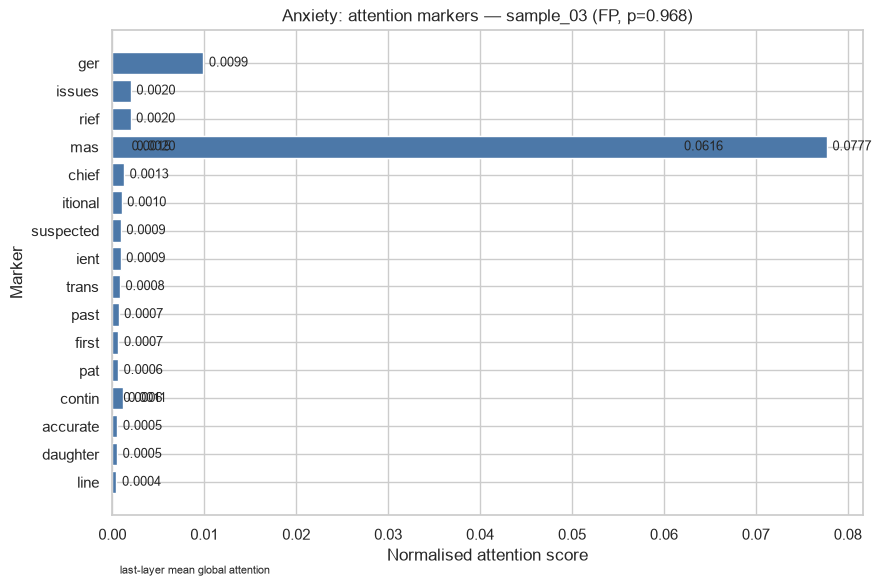

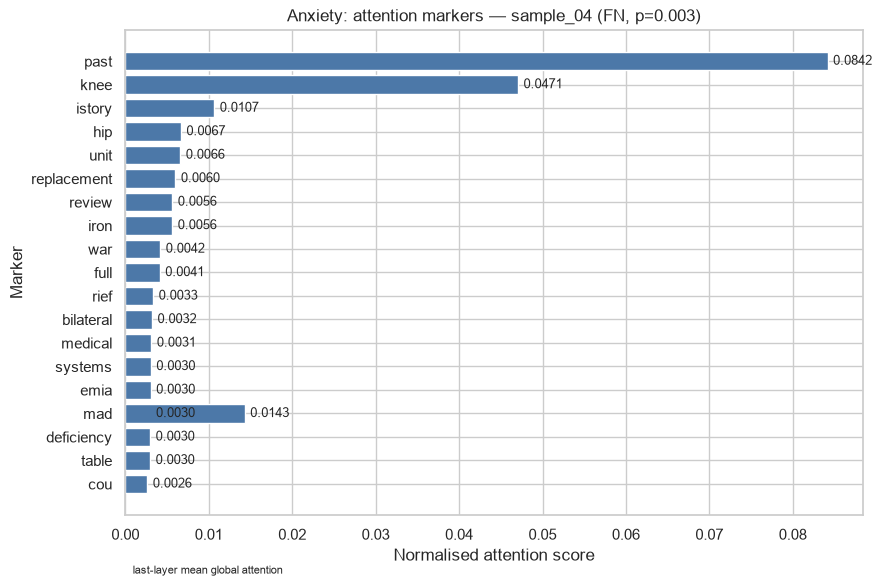

In [15]:
for task in TASKS:
    rows = attention_rows_by_task[task]
    for sample_id, sample_rows in rows.groupby("sample_id", sort=False):
        plot_rows = sample_rows.loc[sample_rows["marker"].ne("")].nlargest(TOP_ATTENTION_MARKERS, "attention_score")
        if plot_rows.empty:
            continue
        plot_rows = plot_rows.sort_values("attention_score")
        figure, axis = plt.subplots(figsize=(9, max(4.5, 0.30 * len(plot_rows))))
        axis.barh(plot_rows["marker"], plot_rows["attention_score"], color="#4C78A8")
        outcome = str(plot_rows.iloc[0]["outcome"])
        probability = float(plot_rows.iloc[0]["positive_probability"])
        method = str(plot_rows.iloc[0]["attention_method"])
        axis.set(title=f"{task.title()}: attention markers — {sample_id} ({outcome}, p={probability:.3f})",
                 xlabel="Normalised attention score", ylabel="Marker")
        axis.text(0.01, -0.12, method, transform=axis.transAxes, fontsize=8)
        label_horizontal_bars(axis, decimals=4)
        figure.tight_layout()
        save_figure(figure, task, f"attention_{sample_id}")
        plt.show()
        plt.close(figure)


### Depression ranked attention markers

,attention_rank,marker,mean_attention,total_attention,maximum_attention,sample_frequency,occurrence_count
0,1,pts,0.019204,0.019204,0.019204,1,1
1,2,lip,0.014935,0.029870,0.029684,2,2
2,3,ral,0.005824,0.011648,0.005959,1,2
3,4,mad,0.003852,0.042371,0.015266,2,11
4,5,illation,0.003296,0.016478,0.009053,2,5
5,6,pert,0.003281,0.016404,0.011522,4,5
6,7,lock,0.003177,0.006354,0.004457,1,2
7,8,code,0.002903,0.005805,0.004855,2,2
8,9,mas,0.002739,0.021909,0.006625,2,8
9,10,ibr,0.002665,0.013324,0.007521,2,5


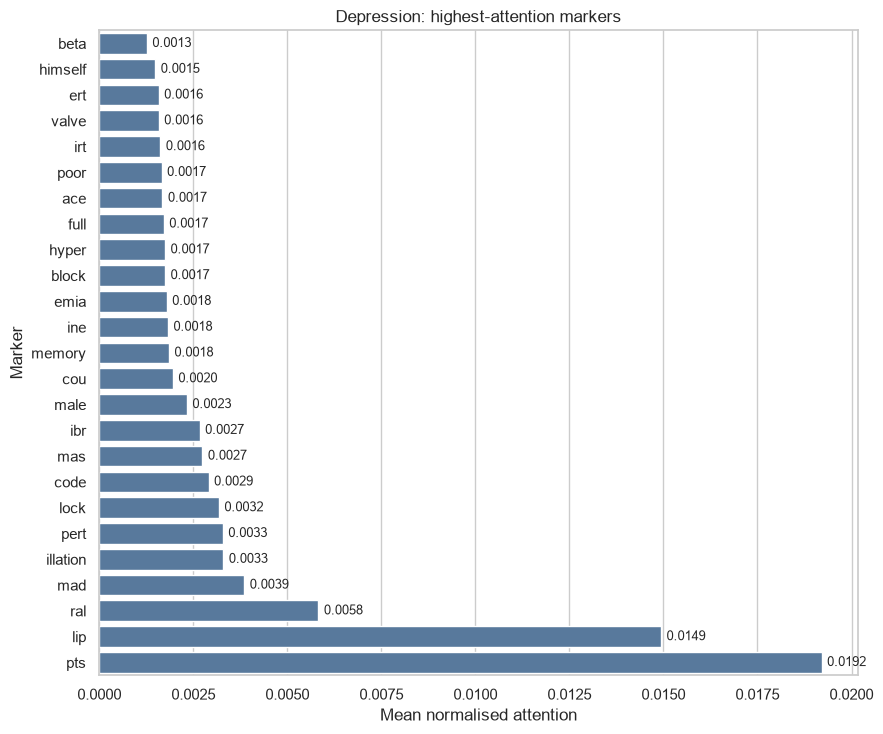

### Anxiety ranked attention markers

,attention_rank,marker,mean_attention,total_attention,maximum_attention,sample_frequency,occurrence_count
0,1,knee,0.047061,0.047061,0.047061,1,1
1,2,past,0.029994,0.209959,0.084163,4,7
2,3,mas,0.028359,0.340308,0.192824,2,12
3,4,ism,0.011446,0.022892,0.022716,1,2
4,5,mad,0.006845,0.047912,0.023811,2,7
5,6,hip,0.006652,0.006652,0.006652,1,1
6,7,review,0.005621,0.005621,0.005621,1,1
7,8,ger,0.004952,0.009905,0.009894,2,2
8,9,replacement,0.004187,0.008373,0.005992,1,2
9,10,bilateral,0.003186,0.003186,0.003186,1,1


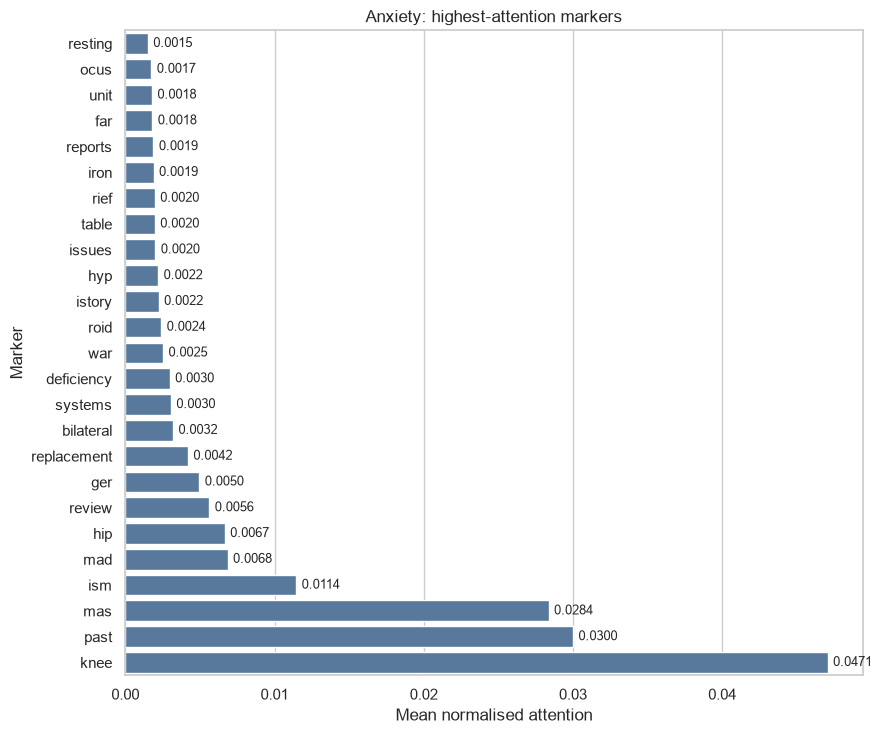

In [16]:
def build_global_attention_table(rows):
    clean = rows.loc[rows["marker"].ne("")].copy()
    grouped = clean.groupby("marker", as_index=False).agg(
        mean_attention=("attention_score", "mean"),
        total_attention=("attention_score", "sum"),
        maximum_attention=("attention_score", "max"),
        sample_frequency=("sample_id", "nunique"),
        occurrence_count=("marker", "size"))
    grouped = grouped.sort_values(["mean_attention", "sample_frequency"], ascending=False).reset_index(drop=True)
    grouped.insert(0, "attention_rank", np.arange(1, len(grouped) + 1))
    return grouped

global_attention_by_task = {}
for task in TASKS:
    table = build_global_attention_table(attention_rows_by_task[task])
    global_attention_by_task[task] = table
    table.to_csv(TASK_DIRS[task]["tables"] / "ranked_attention_markers.csv", index=False)
    display(Markdown(f"### {task.title()} ranked attention markers"))
    display(table.head(TOP_GLOBAL_MARKERS).round(6))
    plot_rows = table.head(TOP_GLOBAL_MARKERS).sort_values("mean_attention")
    figure, axis = plt.subplots(figsize=(9, max(6, 0.30 * len(plot_rows))))
    sns.barplot(data=plot_rows, x="mean_attention", y="marker", color="#4C78A8", ax=axis)
    axis.set(title=f"{task.title()}: highest-attention markers",
             xlabel="Mean normalised attention", ylabel="Marker")
    label_horizontal_bars(axis, decimals=4)
    figure.tight_layout()
    save_figure(figure, task, "global_attention_marker_ranking")
    plt.show()
    plt.close(figure)


## 8. Combined marker report

SHAP is treated as the primary attribution method. Attention is secondary supporting evidence. The combined score is a transparent descriptive ranking: 75% normalised mean absolute SHAP and 25% normalised mean attention. It is not a clinical risk coefficient.


### Depression combined marker report

,combined_rank,marker,combined_interpretability_score,mean_absolute_shap,mean_attention,model_direction
0,1,years,0.751225,0.016698,0.000094,toward positive class
1,2,discharged,0.650654,0.014484,0.000006,toward positive class
2,3,pts,0.250283,0.000006,0.019204,away from positive class
3,4,lip,0.203862,0.000210,0.014935,toward positive class
4,5,mas,0.194172,0.003529,0.002739,toward positive class
5,6,appeared,0.123025,0.002718,0.000073,toward positive class
6,7,ral,0.119119,0.000964,0.005824,toward positive class
7,8,affect,0.114731,0.002541,0.000047,toward positive class
8,9,flat,0.103595,0.002299,0.000024,toward positive class
9,10,home,0.067725,0.001474,0.000117,toward positive class


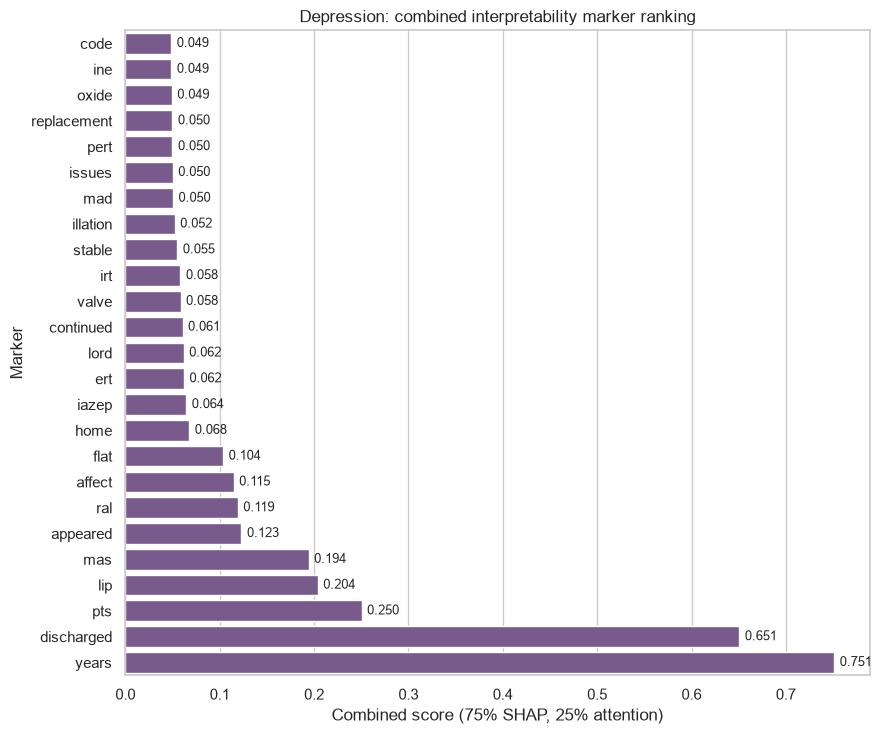

### Anxiety combined marker report

,combined_rank,marker,combined_interpretability_score,mean_absolute_shap,mean_attention,model_direction
0,1,takes,0.750000,0.006371,0.000000,toward positive class
1,2,mas,0.626318,0.004041,0.028359,toward positive class
2,3,knee,0.256079,0.000052,0.047061,away from positive class
3,4,past,0.207876,0.000413,0.029994,away from positive class
4,5,flat,0.196513,0.001670,0.000000,toward positive class
5,6,taking,0.155236,0.001319,0.000000,toward positive class
6,7,including,0.150247,0.001277,0.000000,toward positive class
7,8,coordinating,0.150247,0.001277,0.000000,toward positive class
8,9,find,0.147357,0.001252,0.000000,toward positive class
9,10,ings,0.147357,0.001252,0.000000,toward positive class


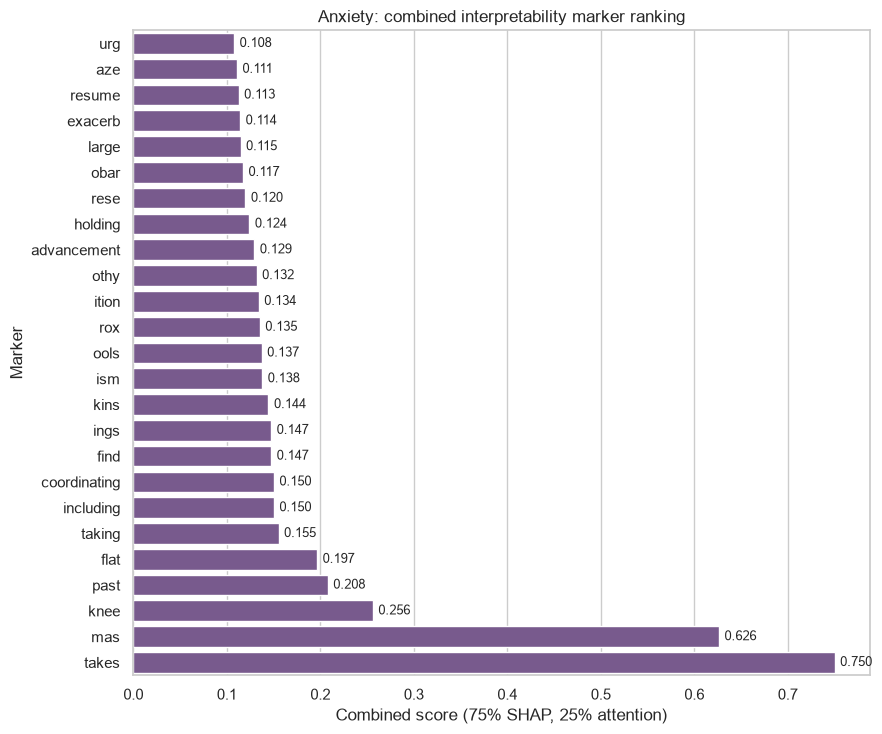

In [17]:
def minmax(series):
    series = pd.to_numeric(series, errors="coerce").fillna(0.0)
    spread = series.max() - series.min()
    return (series - series.min()) / spread if spread > 0 else pd.Series(np.ones(len(series)), index=series.index)

combined_markers_by_task = {}
for task in TASKS:
    shap_table = global_shap_by_task[task].copy()
    attention_table = global_attention_by_task[task].copy()
    combined = shap_table.merge(attention_table, on="marker", how="outer")
    combined["mean_absolute_shap"] = combined["mean_absolute_shap"].fillna(0.0)
    combined["mean_signed_shap"] = combined["mean_signed_shap"].fillna(0.0)
    combined["mean_attention"] = combined["mean_attention"].fillna(0.0)
    combined["normalised_shap"] = minmax(combined["mean_absolute_shap"])
    combined["normalised_attention"] = minmax(combined["mean_attention"])
    combined["combined_interpretability_score"] = 0.75 * combined["normalised_shap"] + 0.25 * combined["normalised_attention"]
    combined = combined.sort_values("combined_interpretability_score", ascending=False).reset_index(drop=True)
    combined.insert(0, "combined_rank", np.arange(1, len(combined) + 1))
    combined["model_direction"] = np.where(combined["mean_signed_shap"].ge(0),
                                           "toward positive class", "away from positive class")
    combined_markers_by_task[task] = combined
    combined.to_csv(TASK_DIRS[task]["tables"] / "ranked_combined_clinical_markers.csv", index=False)
    display(Markdown(f"### {task.title()} combined marker report"))
    display(combined.head(TOP_GLOBAL_MARKERS)[["combined_rank", "marker", "combined_interpretability_score",
                                               "mean_absolute_shap", "mean_attention", "model_direction"]].round(6))
    plot_rows = combined.head(TOP_GLOBAL_MARKERS).sort_values("combined_interpretability_score")
    figure, axis = plt.subplots(figsize=(9, max(6, 0.30 * len(plot_rows))))
    sns.barplot(data=plot_rows, x="combined_interpretability_score", y="marker",
                color=MODEL_COLORS[best_model_by_task[task]], ax=axis)
    axis.set(title=f"{task.title()}: combined interpretability marker ranking",
             xlabel="Combined score (75% SHAP, 25% attention)", ylabel="Marker")
    label_horizontal_bars(axis, decimals=3)
    figure.tight_layout()
    save_figure(figure, task, "combined_marker_ranking")
    plt.show()
    plt.close(figure)


## 9. Clinical validity sanity check

The following step performs a conservative lexical comparison against concepts described by authoritative or peer-reviewed sources. A lexical match means only that the marker is consistent with a known symptom or late-life context; it is **not** independent clinical validation.

Markers without a match remain in the report as `requires clinical review`. Medication names, template headings and coding artefacts should be reviewed separately because they may represent documentation practices or label leakage.


In [18]:
LITERATURE_REFERENCES = pd.DataFrame([
    {"reference_id": "NIA_Depression_2025", "task": "depression", "source": "National Institute on Aging",
     "title": "Depression and Older Adults", "url": "https://www.nia.nih.gov/health/mental-and-emotional-health/depression-and-older-adults"},
    {"reference_id": "Devita_2022", "task": "depression", "source": "Peer-reviewed review",
     "title": "Recognizing Depression in the Elderly: Practical Guidance and Challenges for Clinical Management",
     "url": "https://pmc.ncbi.nlm.nih.gov/articles/PMC9741828/"},
    {"reference_id": "HusainKrautter_2021", "task": "depression", "source": "Peer-reviewed review",
     "title": "Late Life Depression: The Essentials and the Essential Distinctions",
     "url": "https://pmc.ncbi.nlm.nih.gov/articles/PMC8475940/"},
    {"reference_id": "NIMH_GAD", "task": "anxiety", "source": "National Institute of Mental Health",
     "title": "Generalized Anxiety Disorder: What You Need to Know",
     "url": "https://www.nimh.nih.gov/health/publications/generalized-anxiety-disorder-gad"},
    {"reference_id": "Bryant_2013", "task": "anxiety", "source": "Peer-reviewed review",
     "title": "Anxiety disorders in older adults: Looking to DSM5 and beyond",
     "url": "https://pmc.ncbi.nlm.nih.gov/articles/PMC4169193/"},
    {"reference_id": "Aggarwal_2017", "task": "anxiety", "source": "Peer-reviewed review",
     "title": "Anxiety in Later Life", "url": "https://pmc.ncbi.nlm.nih.gov/articles/PMC6526970/"},
])
LITERATURE_REFERENCES.to_csv(OUTPUT_ROOT / "literature_references.csv", index=False)

CONCEPTS = {
    "depression": {
        "affective symptoms": ["depress", "sad", "hopeless", "helpless", "worthless", "guilt", "anhedonia", "interest", "irritable"],
        "self-harm and suicidality": ["suicid", "self harm", "self-harm", "death wish"],
        "sleep, appetite and energy": ["sleep", "insomnia", "appetite", "fatigue", "energy", "weight"],
        "cognitive or somatic presentation": ["cognitive", "memory", "concentration", "confusion", "dementia", "pain", "somatic"],
        "late-life social context": ["lonely", "loneliness", "isolat", "bereave", "grief", "widow", "loss", "frail", "disability"],
    },
    "anxiety": {
        "worry, fear and nervousness": ["anx", "worry", "worried", "fear", "panic", "nervous", "apprehens", "doom"],
        "restlessness and arousal": ["restless", "agitat", "tremor", "trembl", "sweat", "palpitation", "tachycard", "dyspnea", "shortness of breath"],
        "sleep and concentration": ["sleep", "insomnia", "fatigue", "concentration", "focus"],
        "avoidance and function": ["avoid", "homebound", "function", "independent", "dependent"],
        "late-life overlap or context": ["fall", "pain", "cognitive", "memory", "dementia", "chronic", "frail", "medication"],
    },
}
REFERENCE_IDS = {"depression": "NIA_Depression_2025; Devita_2022; HusainKrautter_2021",
                 "anxiety": "NIMH_GAD; Bryant_2013; Aggarwal_2017"}

def concept_match(task, marker):
    marker_lower = str(marker).lower()
    matches = [category for category, terms in CONCEPTS[task].items()
               if any(term in marker_lower for term in terms)]
    return "; ".join(matches)


### Depression clinical validity sanity check

,combined_rank,marker,model_direction,literature_concept,sanity_check_status,reference_ids
0,1,years,toward positive class,,requires clinical review,
1,2,discharged,toward positive class,,requires clinical review,
2,3,pts,away from positive class,,requires clinical review,
3,4,lip,toward positive class,,requires clinical review,
4,5,mas,toward positive class,,requires clinical review,
5,6,appeared,toward positive class,,requires clinical review,
6,7,ral,toward positive class,,requires clinical review,
7,8,affect,toward positive class,,requires clinical review,
8,9,flat,toward positive class,,requires clinical review,
9,10,home,toward positive class,,requires clinical review,


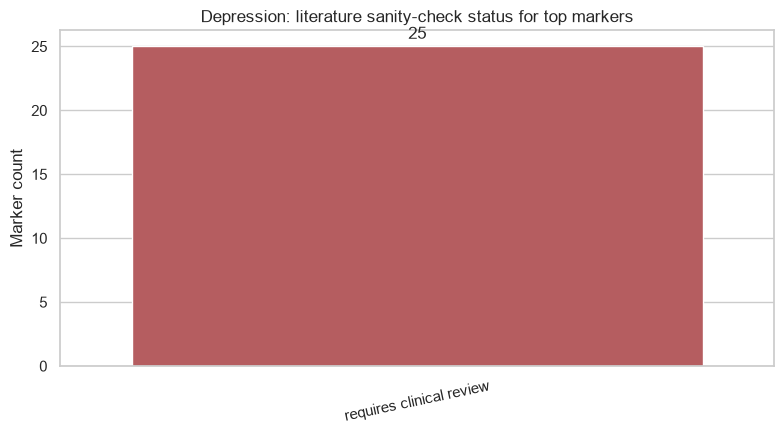

### Anxiety clinical validity sanity check

,combined_rank,marker,model_direction,literature_concept,sanity_check_status,reference_ids
0,1,takes,toward positive class,,requires clinical review,
1,2,mas,toward positive class,,requires clinical review,
2,3,knee,away from positive class,,requires clinical review,
3,4,past,away from positive class,,requires clinical review,
4,5,flat,toward positive class,,requires clinical review,
5,6,taking,toward positive class,,requires clinical review,
6,7,including,toward positive class,,requires clinical review,
7,8,coordinating,toward positive class,,requires clinical review,
8,9,find,toward positive class,,requires clinical review,
9,10,ings,toward positive class,,requires clinical review,


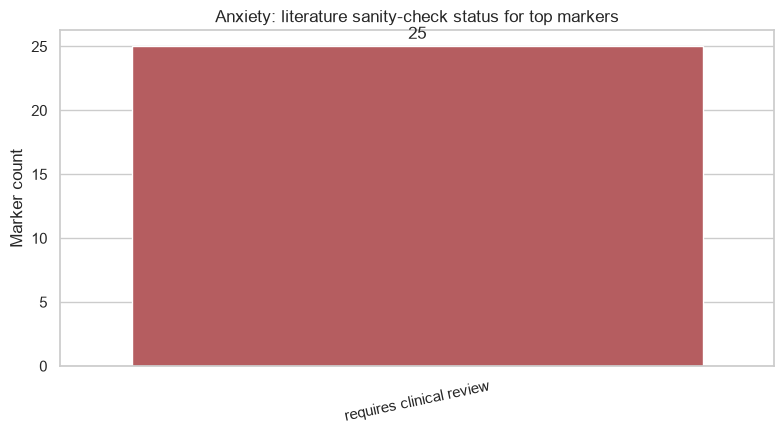

In [19]:
validity_by_task = {}
for task in TASKS:
    table = combined_markers_by_task[task].head(max(50, TOP_GLOBAL_MARKERS)).copy()
    table["literature_concept"] = table["marker"].map(lambda marker: concept_match(task, marker))
    table["sanity_check_status"] = np.where(table["literature_concept"].ne(""),
                                             "literature-consistent lexical match", "requires clinical review")
    table["reference_ids"] = np.where(table["literature_concept"].ne(""), REFERENCE_IDS[task], "")
    table["clinical_interpretation"] = "Model-behaviour marker only; not causal and not diagnostic"
    validity_by_task[task] = table
    table.to_csv(TASK_DIRS[task]["tables"] / "clinical_marker_validity_check.csv", index=False)
    display(Markdown(f"### {task.title()} clinical validity sanity check"))
    display(table.head(TOP_GLOBAL_MARKERS)[["combined_rank", "marker", "model_direction",
                                           "literature_concept", "sanity_check_status", "reference_ids"]])
    counts = table.head(TOP_GLOBAL_MARKERS)["sanity_check_status"].value_counts().rename_axis("status").reset_index(name="markers")
    figure, axis = plt.subplots(figsize=(8, 4.5))
    sns.barplot(data=counts, x="status", y="markers", hue="status", legend=False,
                palette={"literature-consistent lexical match": "#55A868", "requires clinical review": "#C44E52"}, ax=axis)
    axis.set(title=f"{task.title()}: literature sanity-check status for top markers", xlabel="", ylabel="Marker count")
    axis.tick_params(axis="x", rotation=12)
    for container in axis.containers:
        axis.bar_label(container, fmt="%.0f", padding=3)
    figure.tight_layout()
    save_figure(figure, task, "clinical_validity_status")
    plt.show()
    plt.close(figure)


## 10. SHAP–attention agreement

Agreement is assessed only for markers observed by both methods. A positive Spearman correlation indicates similar ordering; low agreement is not automatically a model failure because SHAP and attention answer different questions.


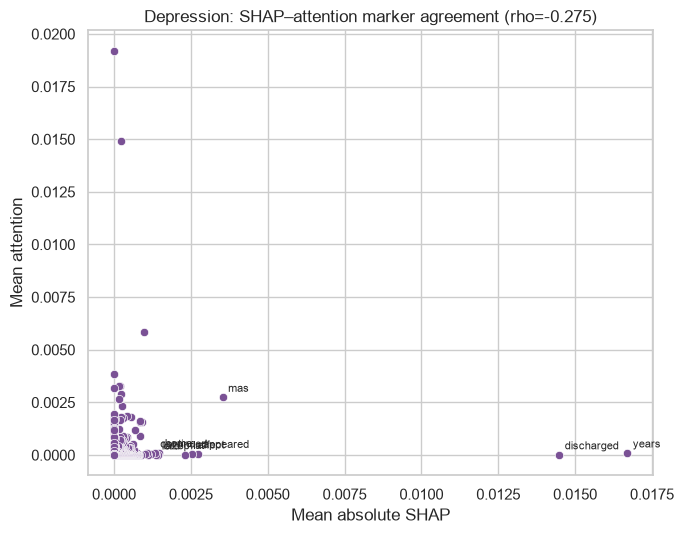

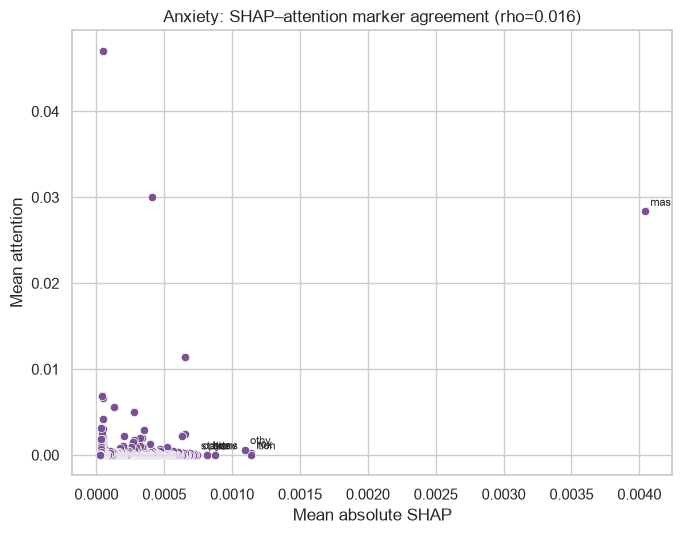

,task,model,common_markers,spearman_correlation,p_value
0,depression,Clinical Longformer,826,-0.27498,0.00000
1,anxiety,Clinical Longformer,887,0.01561,0.64242


In [20]:
agreement_rows = []
for task in TASKS:
    common = global_shap_by_task[task][["marker", "mean_absolute_shap"]].merge(
        global_attention_by_task[task][["marker", "mean_attention"]], on="marker", how="inner")
    if len(common) >= 3:
        correlation, p_value = spearmanr(common["mean_absolute_shap"], common["mean_attention"])
    else:
        correlation, p_value = np.nan, np.nan
    agreement_rows.append({"task": task, "model": best_model_by_task[task], "common_markers": len(common),
                           "spearman_correlation": correlation, "p_value": p_value})
    figure, axis = plt.subplots(figsize=(7, 5.5))
    sns.scatterplot(data=common, x="mean_absolute_shap", y="mean_attention", color=MODEL_COLORS[best_model_by_task[task]], ax=axis)
    for _, row in common.nlargest(min(10, len(common)), "mean_absolute_shap").iterrows():
        axis.annotate(row["marker"], (row["mean_absolute_shap"], row["mean_attention"]),
                      xytext=(4, 4), textcoords="offset points", fontsize=8)
    axis.set(title=f"{task.title()}: SHAP–attention marker agreement (rho={correlation:.3f})" if np.isfinite(correlation)
                   else f"{task.title()}: SHAP–attention marker agreement",
             xlabel="Mean absolute SHAP", ylabel="Mean attention")
    figure.tight_layout()
    save_figure(figure, task, "shap_attention_agreement")
    plt.show()
    plt.close(figure)
agreement_table = pd.DataFrame(agreement_rows)
agreement_table.to_csv(OUTPUT_ROOT / "shap_attention_agreement.csv", index=False)
display(agreement_table.round(5))


## 11. Save the interpretability methodology and dashboard manifest

The methodology file documents model/checkpoint selection, sample selection, attribution settings, aggregation, clinical sanity checking and limitations. The dashboard manifests list every export without embedding raw note text.


In [21]:
methodology = f"""# Interpretability methodology

## Scope
This analysis explains the Week 9 point-estimate PR-AUC leader separately for depression and anxiety. No model was retrained or retuned. Each task used its saved best-validation checkpoint and the same masked selected-text input used during model training.

## Representative samples
Test notes were selected reproducibly from true-positive, true-negative, false-positive and false-negative outcomes. Within each available outcome, selection used prediction confidence only. Full mode selected up to {SHAP_SAMPLES_PER_OUTCOME} notes per outcome; smoke mode used one.

## SHAP
SHAP PartitionExplainer used the model tokenizer as a text masker and explained positive-class probability. The maximum evaluation budget was {SHAP_MAX_EVALS} per note. Values are approximate local attributions. Global marker rankings aggregate absolute local SHAP values across this audit sample.

## Attention
Standard models used last-layer mean attention from the first classification token. Clinical Longformer used last-layer mean global attention for the first globally attended token. Attention is a diagnostic of information routing and is not equivalent to feature importance.

## Combined marker ranking
The descriptive combined score assigns 75% weight to normalised mean absolute SHAP and 25% to normalised mean attention. This score is not a clinical coefficient.

## Clinical validity sanity check
Top markers were lexically compared with symptom and late-life context concepts from NIA, NIMH and peer-reviewed reviews. A match indicates literature consistency only. Non-matches require clinical review. All markers require review for negation, note-template artefacts, medication proxies and label leakage.

## Limitations
- The cohort contains adults aged 65+, so markers are geriatric-cohort markers; geriatric specificity cannot be established without a younger comparison cohort.
- SHAP and attention do not establish causality or diagnostic validity.
- Explanations depend on the selected checkpoint, preprocessing, context length and sample-selection rule.
- Aggregated subword markers can be unstable and must be checked in their original masked-note context.
- No raw note text is exported by this notebook.
"""
methodology_path = OUTPUT_ROOT / "interpretability_methodology.md"
methodology_path.write_text(methodology, encoding="utf-8")
print("Saved methodology:", methodology_path)

for task in TASKS:
    files = sorted(path for path in TASK_DIRS[task]["tables"].glob("*") if path.is_file())
    files += sorted(path for path in TASK_DIRS[task]["figures"].glob("*") if path.is_file())
    manifest = {"task": task, "model": best_model_by_task[task], "checkpoint_stage": "best validation",
                "run_mode": RUN_MODE, "contains_raw_note_text": False,
                "files": [{"path": str(path.relative_to(OUTPUT_ROOT)), "type": path.suffix.lstrip(".")}
                          for path in files]}
    with open(TASK_DIRS[task]["dashboard"] / "dashboard_manifest.json", "w", encoding="utf-8") as output_file:
        json.dump(manifest, output_file, indent=2)


Saved methodology: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/interpretability_analysis/interpretability_methodology.md


In [22]:
inventory_rows = []
for task in TASKS:
    for path in sorted(TASK_DIRS[task]["tables"].glob("*")) + sorted(TASK_DIRS[task]["figures"].glob("*")):
        if path.is_file():
            inventory_rows.append({"task": task, "category": path.parent.name,
                                   "file": str(path.relative_to(OUTPUT_ROOT)),
                                   "size_mb": path.stat().st_size / 1_048_576})
inventory = pd.DataFrame(inventory_rows)
inventory.to_csv(OUTPUT_ROOT / "output_inventory.csv", index=False)
for task in TASKS:
    display(Markdown(f"### {task.title()} output inventory"))
    display(inventory.loc[inventory["task"].eq(task)].reset_index(drop=True).round(3))


### Depression output inventory

,task,category,file,size_mb
0,depression,tables,depression/tables/clinical_marker_validity_che...,0.017
1,depression,tables,depression/tables/local_attention_scores.csv,0.525
2,depression,tables,depression/tables/local_shap_attributions.csv,1.357
3,depression,tables,depression/tables/ranked_attention_markers.csv,0.064
4,depression,tables,depression/tables/ranked_combined_clinical_mar...,0.307
5,depression,tables,depression/tables/ranked_shap_markers.csv,0.160
6,depression,tables,depression/tables/representative_sample_manife...,0.000
7,depression,figures,depression/figures/attention_sample_01.png,0.116
8,depression,figures,depression/figures/attention_sample_01.svg,0.054
9,depression,figures,depression/figures/attention_sample_02.png,0.133


### Anxiety output inventory

,task,category,file,size_mb
0,anxiety,tables,anxiety/tables/clinical_marker_validity_check.csv,0.014
1,anxiety,tables,anxiety/tables/local_attention_scores.csv,0.624
2,anxiety,tables,anxiety/tables/local_shap_attributions.csv,1.486
3,anxiety,tables,anxiety/tables/ranked_attention_markers.csv,0.069
4,anxiety,tables,anxiety/tables/ranked_combined_clinical_marker...,0.318
5,anxiety,tables,anxiety/tables/ranked_shap_markers.csv,0.166
6,anxiety,tables,anxiety/tables/representative_sample_manifest.csv,0.000
7,anxiety,figures,anxiety/figures/attention_sample_01.png,0.135
8,anxiety,figures,anxiety/figures/attention_sample_01.svg,0.061
9,anxiety,figures,anxiety/figures/attention_sample_02.png,0.136


## 12. Final deliverable summary

Use the task-specific CSV tables for the ranked clinical marker report and the PNG/SVG files for the dashboard. Before client delivery, a clinician should review the top positive and negative SHAP markers in their masked-note context and document any likely template, medication or coding proxies.


In [23]:
final_rows = []
for task in TASKS:
    combined = combined_markers_by_task[task]
    validity = validity_by_task[task]
    final_rows.append({"task": task, "selected_model": best_model_by_task[task],
                       "checkpoint_stage": "best validation",
                       "representative_notes_explained": representative_samples[task]["sample_id"].nunique(),
                       "ranked_markers": len(combined),
                       "top_marker": combined.iloc[0]["marker"] if len(combined) else "Not available",
                       "top_marker_direction": combined.iloc[0]["model_direction"] if len(combined) else "Not available",
                       "literature_matched_top_markers": int(validity.head(TOP_GLOBAL_MARKERS)["literature_concept"].ne("").sum()),
                       "markers_requiring_clinical_review": int(validity.head(TOP_GLOBAL_MARKERS)["literature_concept"].eq("").sum())})
final_summary = pd.DataFrame(final_rows)
final_summary.to_csv(OUTPUT_ROOT / "interpretability_summary.csv", index=False)
for task in TASKS:
    display(Markdown(f"### {task.title()} final summary"))
    display(final_summary.loc[final_summary["task"].eq(task)].reset_index(drop=True))
print("Week 10 interpretability outputs saved to:", OUTPUT_ROOT)


### Depression final summary

,task,selected_model,checkpoint_stage,representative_notes_explained,ranked_markers,top_marker,top_marker_direction,literature_matched_top_markers,markers_requiring_clinical_review
0,depression,Clinical Longformer,best validation,8,1331,years,toward positive class,0,25


### Anxiety final summary

,task,selected_model,checkpoint_stage,representative_notes_explained,ranked_markers,top_marker,top_marker_direction,literature_matched_top_markers,markers_requiring_clinical_review
0,anxiety,Clinical Longformer,best validation,8,1370,takes,toward positive class,0,25


Week 10 interpretability outputs saved to: /Users/purnaperamune/Documents/GitHub/P000464SE-Modern-Transformer-Models-for-Depression-Anxiety-Detection/model_outputs/interpretability_analysis


## References used for the clinical plausibility screen

- National Institute on Aging. [Depression and Older Adults](https://www.nia.nih.gov/health/mental-and-emotional-health/depression-and-older-adults).
- Devita M, et al. [Recognizing Depression in the Elderly: Practical Guidance and Challenges for Clinical Management](https://pmc.ncbi.nlm.nih.gov/articles/PMC9741828/).
- Husain-Krautter S, et al. [Late Life Depression: The Essentials and the Essential Distinctions](https://pmc.ncbi.nlm.nih.gov/articles/PMC8475940/).
- National Institute of Mental Health. [Generalized Anxiety Disorder: What You Need to Know](https://www.nimh.nih.gov/health/publications/generalized-anxiety-disorder-gad).
- Bryant C, et al. [Anxiety disorders in older adults: Looking to DSM5 and beyond](https://pmc.ncbi.nlm.nih.gov/articles/PMC4169193/).
- Aggarwal R, et al. [Anxiety in Later Life](https://pmc.ncbi.nlm.nih.gov/articles/PMC6526970/).
